#----------Environment configuration------------------------------




# 1. Open this link https://colab.research.google.com/ -> upload notebook

In [ ]:
%pip uninstall -y pyspark py4j

In [ ]:
%pip install -q "pyspark[connect]==4.0.1" kaggle pyarrow

In [ ]:

import os
import pyspark
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder
    .appName("IIoT_BigData_CA")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)

spark.range(5).show()


In [ ]:
import pyspark
import sys

print("Python:", sys.version)
print("PySpark:", pyspark.__version__)

# **`Course Assignment (CA) Topic:`** ***Distributed Big Data processing for neural network-based anomaly detection in the Industrial Internet of Things (IIoT).***

**`Module Breakdown`**

* **MLO 1:** Critically evaluate data storage and management requirements.
* **MLO 2:** Evaluate distributed architecture patterns and technology stack components.
* **MLO 3:** Select and evaluate a Big Data environment in terms of scalability and speed.

This notebook reproduces the storage/processing experiments. **Apache Spark is run in local mode within Colab, rather than on a multi-node cluster.**

> The experiment measures *data processing*, not the distributed training of neural networks.

Execute the environment configuration cells, then run the remaining cells from top to bottom.

# **1.1 Research Question to be Investigated in This Notebook**

> `How do the choice of storage format and parallel processing technologies influence storage efficiency, scalability, and computational performance when applied to cybersecurity data in Industrial IoT (IIoT) environments?`

# **1.2 Specific Objectives of This Research**

> 1. Analyze the requirements necessary for storing and managing a dataset.

> 2. Conduct performance tests comparing CSV and Apache Parquet based on three key criteria:
- File size.
- Write time.
- Read performance.

> 3. Explore Apache Spark, testing functionalities such as partitioning, query optimization, and data redistribution.

> 4. Compare Pandas and PySpark using statistical operations.

> 5. Perform tests across datasets of varying sizes—specifically 200,000, 500,000, and 1,000,000 records—to evaluate processing scalability.

> 6. Analyze the results produced by both technologies (Pandas and PySpark).

> 7. Finally, conduct a rigorous and thorough assessment of the suitability and limitations of the investigated technologies (Pandas and PySpark) in efficiently supporting an anomaly detection system based on neural networks. # **1.3 Scope of the investigation**

This notebook aims to analyze the following stages:

- Storage
- Management
- Computational data processing


> Note: It is important to mention that the neural network architecture, model training, optimization of classification thresholds, and evaluation of predictive performance are addressed separately in the notebook titled "Advanced Data Analytics."

The experimental analyses were conducted using Google Colab, which provides access to TPUs (Tensor Processing Units). TPUs are accelerators developed by Google, designed specifically to speed up calculations for artificial intelligence and large-scale neural networks. This enabled me to carry out the required tests and work with large datasets, with Apache Spark running in local parallel execution mode.

Another important point is that, although Spark supports distributed processing across multiple machines, the experiments presented here did not utilize a multi-node cluster. While the results obtained allowed for an evaluation of local parallel processing and Spark’s internal execution mechanisms, they did not allow for an experimental demonstration of the horizontal scalability of a distributed cluster.

<font color="Blue" size="6"> **Module 1 — Big Data Storage and Processing**</font>

# **2. Dataset Acquisition and Characterization**

# **2.1 Origin and description of the dataset**

The dataset used in this work is called Edge-IIoTset, developed by Ferrag et al. (2022). Its primary objective is to support research related to cybersecurity within Internet of Things (IoT) and Industrial Internet of Things (IIoT) environments.

Edge-IIoTset was constructed using an experimental infrastructure that integrates IoT/IIoT devices, communication protocols, and various cyberattack scenarios. The collected records represent network traffic characteristics, enabling the investigation of patterns associated with both legitimate and malicious activities (Ferrag, 2022).

This dataset was selected because it aligns well with the specific objectives of this research, providing data that can be utilized both for Big Data processing experiments and for the development of anomaly detection models based on neural networks.

Another positive aspect of this dataset is that it is publicly available—specifically on Kaggle—which facilitates its use in academic research and experiments.

**Reference:**

Ferrag, Mohamed Amine, et al. "Edge-IIoTset: A new comprehensive realistic cyber security dataset of IoT and IIoT applications for centralized and federated learning." IEEe Access 10 (2022): 40281-40306.

**Repositório de aquisição:**

https://www.kaggle.com/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-**iiot**

#**2.2 Data Acquisition**

As previously mentioned, the data acquisition process was carried out using the official Kaggle API. This process was developed within the Google Colab execution environment, which offers advantages in terms of management and processing power—notably through the TPUs available on the platform.

> # Database Configuration Process

1. First, it was necessary to create a Kaggle account, log in, and download a configuration file named `kaggle.json`. This file serves as a credential document, which can be obtained from one's Kaggle account.
  > ** To execute this part of the code, simply upload the `kaggle.json` file, which is located in the same folder and repository as the notebook.**

2. The file is then uploaded to the Colab environment and stored in the API configuration directory, with restricted access permissions.

3. Following authentication, the `kaggle datasets download` command was used to retrieve the files available in the Edge-IIoTset repository.

4. The content was stored in the `/content/data` directory; this setup allowed for the organization of the files used throughout the experiments.

5. Since the downloaded dataset contained numerous compressed files, it was necessary to implement a procedure to inspect the ZIP archives in order to identify and extract the specific file of interest:

- `DNN-EdgeIIoT-dataset.csv`

> We selected this specific file because it contains structured records suitable for deep learning applications and network traffic classification.

The entire acquisition process was automated using Python scripts, enabling the process to be reproduced in new Google Colab sessions, provided that the necessary credentials and repository access are available.

In [ ]:
from google.colab import files
from pathlib import Path
import os
import shutil

# Upload of credentials
uploaded = files.upload()

# Identifies the actual name of the uploaded file
uploaded_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".json")
]

if not uploaded_files:
    raise FileNotFoundError(
        "Nenhum arquivo JSON foi enviado."
    )

uploaded_name = uploaded_files[0]

# Create Kaggle configuration directory
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)

# Copy the uploaded file to the name expected by the API
shutil.copy(
    Path("/content") / uploaded_name,
    kaggle_dir / "kaggle.json"
)

# Protecting credentials
os.chmod(kaggle_dir / "kaggle.json", 0o600)

print("Kaggle successfully configured!")
print("Configuration file installed.")


Saving kaggle.json to kaggle.json
Kaggle configurado com sucesso!
Arquivo de configuração instalado.


In [ ]:
import subprocess
from pathlib import Path

DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATASET_SLUG = (
    "mohamedamineferrag/"
    "edgeiiotset-cyber-security-dataset-of-iot-iiot"
)

subprocess.run(
    [
        "kaggle",
        "datasets",
        "download",
        "-d", DATASET_SLUG,
        "-p", str(DATA_DIR)
    ],
    check=True
)

print("Download finalizado!")

for file in DATA_DIR.iterdir():
    if file.is_file():
        size_mb = file.stat().st_size / (1024 * 1024)
        print(f"{file.name}: {size_mb:.2f} MB")

Download finalizado!
edgeiiotset-cyber-security-dataset-of-iot-iiot.zip: 1665.69 MB


**2.3 Dataset Volume and Dimensions**

The original file contains a total of 2,219,201 records and 63 columns, as identified in the tests described below.

Based on these figures, we began investigating strategies for data storage, management, and processing at various scales.
> A key strength of this work is the ability to conduct experiments using varying numbers of records, allowing for an assessment of how different technologies perform as the volume of data increases.

In doing so, we addressed three core concepts:
> **Storage** -> We compared CSV and Parquet formats in terms of storage footprint and the time required to read and write data.

> **Management** -> We organized the files, selected specific attributes, handled invalid values, and prepared representative samples.

> **Processing** -> We compared the execution times of pandas and PySpark as the number of records increased.

For this project, we utilized a dataset containing approximately 2.2 million records. From this, we extracted samples of various sizes to conduct our experiments:

- 200,000 records: Selected to evaluate performance with a smaller volume of data.
- 500,000 records: Selected to observe system behavior with an intermediate volume of data.
- 1,000,000 records: Selected to investigate the impact of a larger volume on total processing time.

The selected dataset consists of 63 columns, including attributes related to network traffic, protocol information, and variables used to identify malicious activity (Ferrag, 2022). During the exploratory testing processes, it was observed that the dataset contains two classification variables that proved to be highly promising, as they provide information regarding the presence and nature of malicious activity within network traffic:

- Attack_label: identifies whether a record represents normal traffic (labeled 0) or malicious traffic (labeled 1).

- Attack_type: identifies the specific category of an attack or indicates normal conditions.

> These two variables have been explored in other studies, such as the research by Ferrag et al. (2022)—creators of the Edge-IIoTset—who developed these labels to support the creation and evaluation of machine learning-based intrusion detection systems.

Subsequent studies have also utilized this classification structure. An interesting example can be found in the paper "A deep learning approach for multiclass attack classification in IoT and IIoT networks using convolutional neural networks" (2025), which investigated various levels of classification, including binary detection and the identification of specific attack categories.

> **Given this information, we have identified these two variables as being highly significant for our current work. They facilitate the development and analysis of binary anomaly detection models, while also enabling the identification of specific attack types and the creation of multi-class classification models.**

> **By distinguishing between these two variables, we aim to understand both the presence and the diversity of malicious activity, thereby establishing a solid foundation for data preparation and subsequent anomaly detection experiments.**

An important note: The `Attack_label` variable was used to perform stratified sampling, ensuring that the class distribution was preserved throughout the experiments.

Reference

1. Ferrag, Mohamed Amine, et al. "Edge-IIoTset: A new comprehensive realistic cyber security dataset of IoT and IIoT applications for centralized and federated learning." IEEe Access 10 (2022): 40281-40306.

2. Seyedkolaei, Ali Abdi, Fatemeh Mahmoudi, and José García. "A deep learning approach for multiclass attack classification in IoT and IIoT networks using convolutional neural networks." Future Internet 17.6 (2025): 230. -< https://www.mdpi.com/1999-5903/17/6/230

In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle configurado com sucesso!")

Kaggle configurado com sucesso!


In [ ]:
import os

os.makedirs("/content/data", exist_ok=True)

!kaggle datasets download \
    -d mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot \
    -p /content/data

print("Download finalizado, se não houver erros acima.")

Dataset URL: https://www.kaggle.com/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot
License(s): CC-BY-NC-SA-4.0
edgeiiotset-cyber-security-dataset-of-iot-iiot.zip: Skipping, found more recently modified local copy (use --force to force download)
Download finalizado, se não houver erros acima.


In [ ]:
#Code to display the values ​​found in the file, without needing to load the entire dataset into memory
from pathlib import Path
import zipfile
import shutil

DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

CSV_NAME = "DNN-EdgeIIoT-dataset.csv"

# 1. Look for an already extracted CSV
matches = list(DATA_DIR.rglob(CSV_NAME))

print("CSVs encontrados antes da extração:")
for path in matches:
    print(path)

# 2. If not found, search inside the ZIP files
if not matches:

    zip_files = list(DATA_DIR.glob("*.zip"))

    print("\nZIPs encontrados:", len(zip_files))

    for zip_path in zip_files:

        print("Verificando ZIP:", zip_path.name)

        with zipfile.ZipFile(zip_path, "r") as z:

            selected = [
                name for name in z.namelist()
                if Path(name).name == CSV_NAME
            ]

            if selected:

                destination = DATA_DIR / CSV_NAME

                with z.open(selected[0]) as source:
                    with destination.open("wb") as target:
                        shutil.copyfileobj(source, target)

                print("CSV extraído:", destination)
                break

    matches = list(DATA_DIR.rglob(CSV_NAME))

# 3. Validate and define the path
if not matches:
    raise FileNotFoundError(
        f"Arquivo {CSV_NAME} não encontrado em {DATA_DIR}. "
        "Verifique se o download do Kaggle foi concluído."
    )

DATASET_PATH = str(matches[0].resolve())

assert Path(DATASET_PATH).is_file()

# 4. Project configuration
OUT = Path("/content/iiot_ca_results")
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42

print("\n========== DATASET CONFIGURATION ==========")
print("DATASET_PATH:", DATASET_PATH)
print("Arquivo existe:", Path(DATASET_PATH).is_file())
print("Tamanho (MB):",
      round(Path(DATASET_PATH).stat().st_size / 2**20, 2))
print("Pasta de resultados:", OUT)
print("===========================================")


CSVs encontrados antes da extração:

ZIPs encontrados: 1
Verificando ZIP: edgeiiotset-cyber-security-dataset-of-iot-iiot.zip
CSV extraído: /content/data/DNN-EdgeIIoT-dataset.csv

========== DATASET CONFIGURATION ==========
DATASET_PATH: /content/data/DNN-EdgeIIoT-dataset.csv
Arquivo existe: True
Tamanho (MB): 1161.02
Pasta de resultados: /content/iiot_ca_results


### 2.2 Dataset Verification and Configuration Phase

Immediately after acquiring and extracting the Edge-IIoTset dataset, we performed a verification step to confirm that the file is available within the Google Colab environment.

The output from the prompt above confirms that the file `DNN-EdgeIIoT-dataset.csv` was located in the `/content/data/` directory and that its size is **1,161.02 MB (approximately 1.16 GB)**.

A variable named `DATASET_PATH` was created and configured to store the path to the original file; this ensures that the dataset remains accessible for various data exploration, preparation, and processing stages later on.

Additionally, a directory named `/content/iiot_ca_results` was defined; this repository will be used to organize the files and results generated by the experiments to be conducted.

This step confirms that the dataset is available and that the paths to be used during execution are correctly configured—a measure that directly contributes to the organization and reproducibility of the experimental process.

In [ ]:

import pandas as pd
import glob
import os

matches = glob.glob(
    "/content/data/**/DNN-EdgeIIoT-dataset.csv",
    recursive=True
)

if not matches:
    raise FileNotFoundError(
        "DNN-EdgeIIoT-dataset.csv not found."
    )

dataset_path = matches[0]

df = pd.read_csv(
    dataset_path,
    nrows=100_000,
    low_memory=False
)

print("Dataset shape:", df.shape)
print("Memory usage (MB):",
      round(df.memory_usage(deep=True).sum() / 1024**2, 2))

display(df.head())


Dataset shape: (100000, 63)
Memory usage (MB): 102.52


,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,...,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,2021 11:44:10.081753000,192.168.0.128,192.168.0.101,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0,Normal
1,2021 11:44:10.162218000,192.168.0.101,192.168.0.128,0,0.0,0.0,0,0.0,0.0,0.0,...,4.0,MQTT,0,0.0,4.0,0.0,0.0,0.0,0,Normal
2,2021 11:44:10.162271000,192.168.0.128,192.168.0.101,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0,Normal
3,2021 11:44:10.162641000,192.168.0.128,192.168.0.101,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0,Normal
4,2021 11:44:10.166132000,192.168.0.101,192.168.0.128,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,Temperature_and_Humidity,24.0,0.0,0.0,0.0,0.0,0,Normal


**2.2.1 Initial Exploration and Structural Characterization of the Data**

Following the acquisition and verification of the `DNN-EdgeIIoT-dataset.csv` file, an initial exploratory analysis was conducted using the `pandas` library to understand the structure and characteristics of the available data.

For this stage, the first 100,000 records were loaded—an initial sample of the original file, which contains approximately 2.2 million observations.

Based on the experiments performed, we were able to extract the following information:

* Records loaded -> 100,000

* Number of attributes -> 63

* DataFrame memory consumption -> 102.52 MB

* Data structure -> Tabular

* Library used -> `pandas`

The dimensions (100,000, 63) indicate that the DataFrame contains 100,000 rows and 63 columns. It is important to note that the 102.52 MB memory footprint reflects how the data is represented within the Python environment, rather than the size of the original CSV file.

A preview of the first five records revealed attributes associated with various communication protocols—including ARP, ICMP, and MQTT—as well as information such as source and destination IP addresses and timestamps.

> ARP, ICMP, and MQTT are communication protocols used in computer networks and IoT (Internet of Things) devices. Each serves a distinct function in facilitating communication between devices. (MINOLI, 2019)

> In our project using the Edge-IIoTset dataset, these protocols are significant because they represent different characteristics of network traffic, which can be analyzed to identify normal behavior versus potential cyberattacks.

A key observation is that the recorded memory usage highlights the importance of considering available computational resources when conducting such experiments. In summary, the initial exploration confirmed the tabular structure of the Edge-IIoTset and allowed us to identify the diversity of attributes present in the dataset. With this information, we were able to establish a solid foundation for the subsequent stages, which include:

- Analysis of data types
- Class distribution
- Feature selection
- Stratified sampling.

**Reference:**

MINOLI, Daniel; SOBERANES, Benedito. IoT Protocol Stack: Architecture and Standards for Smart Devices. New York: CRC Press, 2019.

In [ ]:

print("Dataset information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 63 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   frame.time                 100000 non-null  object 
 1   ip.src_host                100000 non-null  object 
 2   ip.dst_host                100000 non-null  object 
 3   arp.dst.proto_ipv4         100000 non-null  object 
 4   arp.opcode                 100000 non-null  float64
 5   arp.hw.size                100000 non-null  float64
 6   arp.src.proto_ipv4         100000 non-null  object 
 7   icmp.checksum              100000 non-null  float64
 8   icmp.seq_le                100000 non-null  float64
 9   icmp.transmit_timestamp    100000 non-null  float64
 10  icmp.unused                100000 non-null  float64
 11  http.file_data             100000 non-null  float64
 12  http.content_length        100000 non-null  float64
 13  http.requ

**2.2.2 Analysis of Data Types and Structural Integrity**

Following an initial exploration of the Edge-IIoTset, we analyzed the DataFrame structure using the `info()` function from the pandas library to identify:

- `Data types`
- `The number of non-null values`
- `Memory consumption`

The analysis of the first 100,000 records, distributed across 63 attributes, yielded the following results:

The data types are:

* float64 —> floating-point numerical values ​​—> 49

* int64 —> integer numerical values ​​—> 2

* object —> textual or other types of values ​​—> 12

These results show a predominance of numerical attributes, which account for approximately 81% of the columns, while the remaining attributes consist of textual information, such as IP addresses, protocol identifiers, and attack categories.

The analysis also revealed an absence of null values ​​within the 100,000 records examined. However, this observation does not guarantee the absence of invalid, infinite, or missing values ​​in other parts of the dataset.

The DataFrame’s memory consumption was approximately 98.4 MiB (equivalent to about 103 MB), highlighting the memory requirements associated with loading the data.

This information was instrumental in guiding the preparation for subsequent experiments—specifically regarding the selection of numerical attributes, data type conversion, and the evaluation of storage and processing strategies.

Furthermore, this characterization underscores the need to account for the heterogeneity of attributes when developing analytical pipelines for Industrial IoT environments.

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Columns with missing values:")
display(missing)

print("Duplicated rows:", df.duplicated().sum())

print("Missing values total:", df.isnull().sum().sum())

Columns with missing values:


,0


Duplicated rows: 0
Missing values total: 0


In [ ]:

print("Possible target columns:")

target_columns = [
    col for col in df.columns
    if "attack" in col.lower()
    or "label" in col.lower()
    or "class" in col.lower()
]

print(target_columns)

for col in target_columns:
    print(f"\nDistribution of {col}:")
    print(df[col].value_counts(dropna=False).head(20))


Possible target columns:
['Attack_label', 'Attack_type']

Distribution of Attack_label:
Attack_label
0    100000
Name: count, dtype: int64

Distribution of Attack_type:
Attack_type
Normal    100000
Name: count, dtype: int64


# Modulo 2

### 3.1 Identification of Classification Variables and Initial Class Distribution

Following the previous stages of structural analysis of the dataset, it became necessary to identify potential classification variables. The Edge-IIoTset dataset consists of 63 columns representing various types of information, which necessitated the identification of target variables.

> Machine learning literature often suggests variables such as `class` and `label` for identifying classes or serving as target variables, while the variable `attack` is typically used to describe malicious activities and attack categories in cybersecurity datasets. It is important to note that this is not a strict rule. In the study "Edge-IIoTset: A New Comprehensive Realistic Cyber ​​Security Dataset of IoT and IIoT Applications for Centralized and Federated Learning"—which serves as our primary reference and is the source of this dataset—the authors define the variables as follows:
- `Attack_label`: A binary variable used to distinguish between normal traffic and attacks.
- `Attack_type`: A variable used to represent attack categories for multi-class classification.

In their work, Moustafa and Slay (2015) introduced the UNSW-NB15 dataset, which includes the variables `label` and `attack_cat`, used to represent traffic status and attack category, respectively. A similar distinction is also addressed by Zoghi et al. (2024), who identify both as target variables in their analysis of the UNSW-NB15 dataset.

We analyzed the distribution of these variables across the first 100,000 records. Consistent with the reference study, which identified `Attack_label` and `Attack_type` as the relevant variables, we obtained the following results:

| Variable | Category | Records |
|---|---|---:|
| Attack_label | 0 — Normal | 100,000 |
| Attack_type | Normal | 100,000 |

As shown by the results, the initial sample consists exclusively of normal traffic records, containing no examples of cyberattacks.

> `It is important to highlight that this observation demonstrates that selecting the first records of the file sequentially did not yield a sample representative of the various classes present in the complete dataset.`

For this reason, it became necessary to implement a **stratified sampling** strategy—which will be described in greater detail during Experiment B2—to select records from different parts of the file while maintaining, as closely as possible, the original distribution between normal and malicious traffic.

By identifying these variables, we have established the foundation for subsequent binary classification experiments, in which we use the `Attack_label` variable as the target variable for our anomaly detection models.

**Reference:**

1. Ferrag, M.A., Friha, O., Hamouda, D., Maglaras, L. and Janicke, H. (2022) 'Edge-IIoTset: A New Comprehensive Realistic Cyber Security Dataset of IoT and IIoT Applications for Centralized and Federated Learning', IEEE Access, 10, pp. 40281–40306. Available at: https://doi.org/10.1109/ACCESS.2022.3165809
2. Moustafa, N. and Slay, J. (2015) 'UNSW-NB15: A Comprehensive Data Set for Network Intrusion Detection Systems', 2015 Military Communications and Information Systems Conference (MilCIS). IEEE. Available at: https://ieeexplore.ieee.org/document/7348942

In [ ]:
print(df.shape)
print(df.columns.tolist())
print(target_columns)

(100000, 63)
['frame.time', 'ip.src_host', 'ip.dst_host', 'arp.dst.proto_ipv4', 'arp.opcode', 'arp.hw.size', 'arp.src.proto_ipv4', 'icmp.checksum', 'icmp.seq_le', 'icmp.transmit_timestamp', 'icmp.unused', 'http.file_data', 'http.content_length', 'http.request.uri.query', 'http.request.method', 'http.referer', 'http.request.full_uri', 'http.request.version', 'http.response', 'http.tls_port', 'tcp.ack', 'tcp.ack_raw', 'tcp.checksum', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn', 'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack', 'tcp.len', 'tcp.options', 'tcp.payload', 'tcp.seq', 'tcp.srcport', 'udp.port', 'udp.stream', 'udp.time_delta', 'dns.qry.name', 'dns.qry.name.len', 'dns.qry.qu', 'dns.qry.type', 'dns.retransmission', 'dns.retransmit_request', 'dns.retransmit_request_in', 'mqtt.conack.flags', 'mqtt.conflag.cleansess', 'mqtt.conflags', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.msg_decoded_as', 'mqtt.msg', 'mqtt.msgtype', 'mqtt.proto_len', 'mqtt.proton

In [ ]:

import pandas as pd

# Read only the target columns in chunks
chunk_size = 100_000

class_counts = pd.Series(dtype="int64")
attack_counts = pd.Series(dtype="int64")
total_rows = 0

for chunk in pd.read_csv(
    dataset_path,
    usecols=["Attack_label", "Attack_type"],
    chunksize=chunk_size
):
    class_counts = class_counts.add(
        chunk["Attack_label"].value_counts(),
        fill_value=0
    )

    attack_counts = attack_counts.add(
        chunk["Attack_type"].value_counts(),
        fill_value=0
    )

    total_rows += len(chunk)

class_counts = class_counts.astype("int64")
attack_counts = attack_counts.astype("int64")

print("Total records:", total_rows)

print("\nBinary classification:")
print(class_counts)

print("\nAttack types:")
print(attack_counts.sort_values(ascending=False))

print("\nClass percentages:")
print((class_counts / total_rows * 100).round(2))


Total records: 2219201

Binary classification:
Attack_label
0    1615643
1     603558
dtype: int64

Attack types:
Attack_type
Normal                   1615643
DDoS_UDP                  121568
DDoS_ICMP                 116436
SQL_injection              51203
Password                   50153
Vulnerability_scanner      50110
DDoS_TCP                   50062
DDoS_HTTP                  49911
Uploading                  37634
Backdoor                   24862
Port_Scanning              22564
XSS                        15915
Ransomware                 10925
MITM                        1214
Fingerprinting              1001
dtype: int64

Class percentages:
Attack_label
0    72.8
1    27.2
dtype: float64


### 3.2 Class Distribution Considering the Complete Dataset

Following the identification of classification variables in the previous section, we analyzed the class distribution using all **2,219,201 records** from the Edge-IIoTset.

Unlike the experiments conducted on previous samples of 100,000 records—which consisted exclusively of normal traffic—this comprehensive analysis identified both normal records and various categories of cyberattacks.

The `Attack_label` variable showed the following distribution:

| Classification | Count | Percentage |
|---|---:|---:|
| Normal traffic (0) | 1,615,643 | 72.8% |
| Malicious traffic (1) | 603,558 | 27.2% |
| **Total** | **2,219,201** | **100%** |

These results reveal a class imbalance, characterized by a predominance of normal records, as shown in the table above.

A more in-depth analysis yielded the following findings:

* Upon examining the `Attack_type` variable, we identified **14 distinct attack categories** (in addition to the "normal" class), including `DDoS`, `SQL Injection`, `Password` (attacks), `Backdoor`, `Ransomware`, and `Man-in-the-Middle` (MITM).

* Among the malicious categories, `DDoS_UDP` and `DDoS_ICMP` attacks accounted for the highest number of records, while `Fingerprinting` and `MITM` were the least represented.

These observations indicate that the dataset contains a wide diversity of threats; however, there are also significant disparities in the number of available examples for each category. Class imbalance is significant for anomaly detection systems, as supervised models may find it easier to identify classes that have a larger number of examples. However, the actual impact of this imbalance depends on the architecture, the training process, and the evaluation metrics employed.

Furthermore, the discrepancy between the distribution of the first 100,000 records and the overall distribution demonstrated that the original dataset should not be sampled by simply selecting the first few rows in sequence.

In light of these findings, a **stratified sampling strategy based on `Attack_label`** was implemented for Experiment B2. This approach preserves the approximate ratio of 72.8% normal traffic to 27.2% malicious traffic within the subsets used for subsequent experiments.

It is important to note that this stratification was performed based on binary classification. Consequently, while it maintains the overall proportion of normal traffic versus attacks, it does not guarantee that the specific proportions for each of the 14 individual attack categories are preserved.

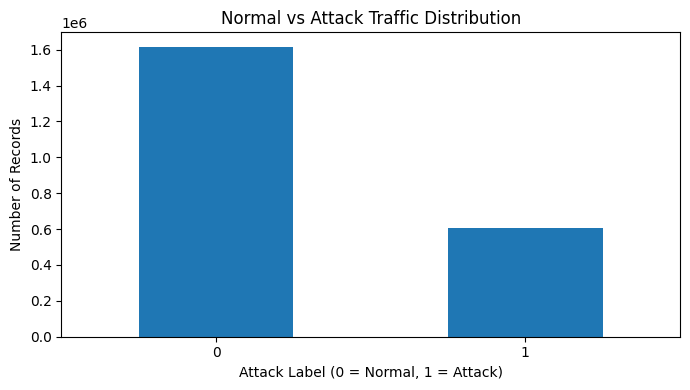

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

class_counts.sort_index().plot(
    kind="bar",
    ax=ax
)

ax.set_title("Normal vs Attack Traffic Distribution")
ax.set_xlabel("Attack Label (0 = Normal, 1 = Attack)")
ax.set_ylabel("Number of Records")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 3.3 Visual Analysis of Class Distribution

Figure 3.1 presents the distribution of normal and malicious traffic records in the Edge-IIoTset dataset, based on the binary classification variable `Attack_label`.

The chart highlights the predominance of normal traffic, accounting for 1,615,643 records (72.8%), compared to 603,558 records classified as attacks (27.2%).

As previously mentioned, this disparity indicates an imbalance between the classes, with approximately 2.7 normal records for every malicious record.

This observed distribution is significant for the subsequent stage of anomaly detection using neural networks, as class imbalance can influence the learning process and the interpretation of classification metrics.

Therefore, in addition to accuracy, metrics such as precision, recall, and F1-score will be essential for evaluating the models' ability to correctly identify malicious records.

In [ ]:

import pandas as pd
import numpy as np

RANDOM_STATE = 42
SAMPLE_SIZE = 200_000
CHUNK_SIZE = 100_000

# Use the full-dataset attack-type counts
type_counts = attack_counts.sort_index()

# Allocate sample quotas proportionally
expected = type_counts / type_counts.sum() * SAMPLE_SIZE
quotas = np.floor(expected).astype(int)

remainder = SAMPLE_SIZE - quotas.sum()
fractional = (expected - quotas).sort_values(ascending=False)

for attack_type in fractional.index[:remainder]:
    quotas.loc[attack_type] += 1

# Streaming reservoir sample per attack type
# Uses bounded memory and avoids loading the full CSV
import random

rng = random.Random(RANDOM_STATE)
reservoirs = {name: [] for name in quotas.index}
seen = {name: 0 for name in quotas.index}

for chunk in pd.read_csv(
    dataset_path,
    chunksize=CHUNK_SIZE,
    low_memory=False
):
    for attack_type, group in chunk.groupby("Attack_type"):
        if attack_type not in quotas.index:
            continue

        target_size = int(quotas.loc[attack_type])
        if target_size == 0:
            continue

        reservoir = reservoirs[attack_type]

        for record in group.to_dict("records"):
            seen[attack_type] += 1
            count = seen[attack_type]

            if len(reservoir) < target_size:
                reservoir.append(record)
            else:
                index = rng.randrange(count)
                if index < target_size:
                    reservoir[index] = record

df_sample = pd.DataFrame([
    record
    for records in reservoirs.values()
    for record in records
])

df_sample = df_sample.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

print("Sample shape:", df_sample.shape)
print("\nClass distribution:")
print(df_sample["Attack_label"].value_counts(normalize=True))
print("\nAttack types:")
print(df_sample["Attack_type"].value_counts())


Sample shape: (200000, 63)

Class distribution:
Attack_label
0    0.72803
1    0.27197
Name: proportion, dtype: float64

Attack types:
Attack_type
Normal                   145606
DDoS_UDP                  10956
DDoS_ICMP                 10493
SQL_injection              4615
Password                   4520
Vulnerability_scanner      4516
DDoS_TCP                   4512
DDoS_HTTP                  4498
Uploading                  3392
Backdoor                   2241
Port_Scanning              2033
XSS                        1434
Ransomware                  985
MITM                        109
Fingerprinting               90
Name: count, dtype: int64


## 3.4 Data Types and Attribute Structure

The Edge-IIoTset features tabular data with various types of attributes, including numerical variables as well as textual or categorical information.

These attributes represent characteristics extracted from network traffic and communication protocols used in IoT and IIoT environments (Ferrag, 2022).

Key groups of attributes present in the dataset include:

**Network protocol attributes:** These represent information associated with protocols such as TCP, UDP, HTTP, ICMP, ARP, and MQTT.

**Numerical attributes:** These consist of values ​​related to packet size, counters, control fields, and communication characteristics.

**Textual or categorical attributes:** These represent information such as network addresses, identifiers, and values ​​associated with specific protocols.

**Classification variables:** These are attributes used to represent normal traffic, malicious traffic, and attack categories.

Examples of columns include:

| Attribute | Description |
|---|---|
| `tcp.ack` | Acknowledgment field associated with the TCP protocol |
| `http.content_length` | Information regarding the size of HTTP content |
| `icmp.checksum` | Checksum field for the ICMP protocol |
| `mqtt.len` | Length information associated with the MQTT protocol |
| `arp.opcode` | Operation code for the ARP protocol |
| `Attack_label` | Binary classification of the traffic |
| `Attack_type` | Category of attack or normal traffic |

The presence of different data types necessitates inspection and transformation procedures before any analytical operations can be performed.

### 3.5 Stratified Sampling and Representativeness Verification

After identifying the class imbalance in the original dataset—as discussed in the previous sections—we applied a stratified sampling strategy to select records that are representative of the various traffic categories.

In the experiment, we generated a sample consisting of **200,000 records and 63 attributes**, while preserving, as closely as possible, the binary distribution observed in the complete Edge-IIoTset.

The resulting distribution is as follows:

| Classification | Records | Percentage |
|---|---:|---:|
| Normal traffic (0) | 145,606 | 72.803% |
| Malicious traffic (1) | 54,394 | 27.197% |
| **Total** | **200,000** | **100%** |

The results show that the sample maintained virtually the same proportion of normal and malicious records as the original dataset—approximately 72.8% and 27.2%, respectively.

Upon analyzing the `Attack_type` variable, we observed the presence of all **14 attack categories** in the sample, including the most common ones: `DDoS`, `SQL Injection`, `Password`, `Backdoor`, `Ransomware`, and `MITM`.

> This observation is significant, as it confirms that the sampling process did not entirely eliminate any of the attack categories present in the original dataset.

However, it should be noted that because the stratification was based on the binary `Attack_label` variable, the exact proportion of each individual attack type is not guaranteed to be preserved.

Employing this strategy helped reduce the bias associated with the sequential selection of records used in the experiments, allowing us to construct a more representative sample for subsequent experimental work. Finally, the results collected during this phase confirm the suitability of stratified sampling for preserving the binary distribution of the classes and supporting the preparation of the data used in storage and processing analyses.

In [ ]:
import pandas as pd
from pathlib import Path

# Check the original file
dataset_file = Path(DATASET_PATH)

assert dataset_file.is_file(), "Dataset não encontrado."

# Counting records without loading the entire CSV into memory
total_rows = 0
total_columns = None

for chunk in pd.read_csv(
    DATASET_PATH,
    chunksize=100_000,
    low_memory=False
):
    total_rows += len(chunk)

    if total_columns is None:
        total_columns = len(chunk.columns)

# Original file size
file_size_mb = dataset_file.stat().st_size / (1024 ** 2)

print("=== DATASET CHARACTERISATION ===")
print(f"Dataset: {dataset_file.name}")
print(f"Total records: {total_rows:,}")
print(f"Total columns: {total_columns}")
print(f"File size: {file_size_mb:.2f} MB")
print(f"Total data cells: {total_rows * total_columns:,}")


=== DATASET CHARACTERISATION ===
Dataset: DNN-EdgeIIoT-dataset.csv
Total records: 2,219,201
Total columns: 63
File size: 1161.02 MB
Total data cells: 139,809,663


In [ ]:
#Checking for the existence of the file and reading the variables

import pandas as pd
from pathlib import Path
import sys
import os
import subprocess
import importlib.metadata

print("Caminho atual:", DATASET_PATH)
print("Arquivo existe:", Path(DATASET_PATH).is_file())

preview = pd.read_csv(
    DATASET_PATH,
    nrows=10_000,
    low_memory=False
)

print("Preview shape:", preview.shape)
print("Número de colunas:", len(preview.columns))
print("Attack_label presente:", "Attack_label" in preview.columns)
print("Attack_type presente:", "Attack_type" in preview.columns)

#File and version check

print("Python:", sys.version)
print("PySpark:", importlib.metadata.version("pyspark"))
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))
print("SPARK_HOME:", os.environ.get("SPARK_HOME"))

result = subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True
)

print("\nJava:")
print(result.stderr or result.stdout)

#File and version check

for file in os.listdir("/content/data"):
    path = os.path.join("/content/data", file)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"{file}: {size_mb:.2f} MB")


Caminho atual: /content/data/DNN-EdgeIIoT-dataset.csv
Arquivo existe: True
Preview shape: (10000, 63)
Número de colunas: 63
Attack_label presente: True
Attack_type presente: True
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PySpark: 4.0.4
JAVA_HOME: None
SPARK_HOME: None

Java:
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)

DNN-EdgeIIoT-dataset.csv: 1161.02 MB
edgeiiotset-cyber-security-dataset-of-iot-iiot.zip: 1665.69 MB


## 3.6 Selection of attributes used in the experiments

Following exploratory analysis, we observed that although the original file contains 63 columns, the Big Data experiments utilized a representation consisting of **50 numerical attributes and one classification variable**, totaling 51 columns.

We selected the numerical attributes by identifying the data types observed during the exploratory analysis using pandas, as shown in the preceding experiments.

> The classification variables were handled separately to prevent their improper inclusion in statistical calculations regarding network characteristics.

> Using numerical attributes allowed us to apply consistent operations—such as calculating the mean and standard deviation—across both pandas and Apache Spark.

This selection also reduced the complexity of the benchmarks while maintaining a consistent data schema across the various data volumes evaluated.

> It is important to note that this specific representation was used exclusively for the storage and processing experiments.

**Note: The Advanced Data Analytics notebook employs a different selection of attributes for training and evaluating neural networks.**

## 3.6 Data quality and missing values

During data preparation, we converted the selected attributes into appropriate numerical formats.

Values ​​incompatible with a numerical representation—as well as infinite values ​​identified during exploratory testing—were converted into missing values.

Within the sample of 1,000,000 records, **70,750 missing cells** were identified among the selected numerical attributes.

> The presence of these values ​​is an important consideration regarding data quality and the selection of analytical operations.

In the experiments developed for this notebook, the mean and standard deviation functions used in both pandas and PySpark excluded these missing values. > Note: In machine learning applications, the presence of missing values ​​requires specific handling strategies—such as imputation—which must be defined according to the model's requirements.

## 3.7 Management and Storage Strategy

Following the acquisition of the original dataset, we implemented a data preparation and storage process for our experiments.

Initially, we selected a stratified sample containing 1,000,000 records, preserving approximately the original class distribution.

We shuffled this sample and used it to generate three datasets of varying sizes:

| Dataset | Records | Columns | Parquet Size |
|---|---:|---:|---:|
| Small dataset | 200,000 | 51 | 4.70 MB |
| Medium dataset | 500,000 | 51 | 10.59 MB |
| Large dataset | 1,000,000 | 51 | 20.30 MB |

The files were stored in the Apache Parquet format.

This strategy allowed for the reuse of the same datasets across performance experiments, ensuring greater consistency in our comparisons.

Furthermore, using the Parquet format enabled us to evaluate the advantages of a columnar storage structure compared to CSV.

## 3.9 Considerations on Reproducibility

We implemented the data acquisition and preparation process using Python scripts and libraries commonly used for data analysis, as shown above.

The key steps include:

1. Configuring Kaggle API credentials.
2. Downloading the Edge-IIoTset repository.
3. Identifying and extracting the selected CSV file.
4. Verifying the data structure and types.
5. Identifying numerical attributes.
6. Applying stratified sampling.
7. Converting and preparing the attributes. 8. Storage of subsets in Apache Parquet.

A fixed random seed (`SEED = 42`) was used to support the reproducibility of the sampling process.

The organization of files carried out in previous steps, along with the definition of storage paths, allowed us to separate data acquisition from subsequent processing stages—a strategy that proved to be excellent.

However, full reproducibility depends on the availability of the same version of the dataset, the same libraries used, and comparable computational conditions.

## 3.10 Final Considerations

The data acquisition and characterization phase established the foundation for the Big Data storage and processing experiments.

The Edge-IIoTset proved suitable for this research, as it provides millions of records, heterogeneous attributes, and information relevant to cybersecurity applications in the Industrial Internet of Things (IIoT).

Using the Kaggle API allowed for the automation of the acquisition process, while attribute inspection and stratified sampling contributed to the preparation of representative datasets.

Converting the data into the Apache Parquet format facilitated the organization of various volumes of information, which were subsequently used in experiments concerning storage, architecture, performance, and scalability.

Thus, the documented process contributes directly to the course's first learning outcome, which relates to the critical evaluation of data storage and management requirements in Big Data projects.

# ========================================================================

**Modulo 3**


## 1. Overview of the Experimental Methodology

## Experimental Methodology Overview

This notebook presents seven experiments designed to evaluate data acquisition, storage efficiency, processing architecture, computational performance, and scalability using the Edge-IIoTset Industrial Internet of Things (IIoT) cybersecurity dataset.

The experiments follow a sequential methodology, beginning with dataset exploration and representative sampling, followed by storage and processing benchmarks, scalability analysis, and numerical validation.

**B1 — Dataset Exploration and Characterization**

The original Edge-IIoTset dataset is acquired and examined to identify its structure, dimensions, data types, and class distribution. This stage establishes the data management requirements and identifies potential challenges, including class imbalance and heterogeneous attributes.

**B2 — Stratified Sampling and Data Preparation**

Representative subsets are generated using stratified sampling based on `Attack_label`. The prepared datasets contain 200,000, 500,000, and 1,000,000 records, preserving approximately the original binary class distribution. Fifty numerical features are selected for subsequent processing experiments.

**B3 — Storage Performance Evaluation**

CSV and Apache Parquet are compared in terms of file size, writing time, and reading performance. The objective is to evaluate whether columnar storage provides measurable benefits for IIoT analytical workloads.

**B4 — Apache Spark Architecture Analysis**

Apache Spark's execution mechanisms are investigated through partition inspection and query execution plans. The experiment examines column pruning, partial aggregation, shuffle operations, and adaptive query execution in local parallel mode.

**B5 — Pandas versus PySpark Performance Benchmark**

Equivalent statistical operations are executed using pandas and PySpark on 200,000 records. Execution times are measured to evaluate the computational overhead and efficiency of each framework.

**B6 — Processing Scalability Evaluation**

The same statistical workload is evaluated across three dataset sizes: 200,000, 500,000, and 1,000,000 records. This experiment investigates how processing time changes as data volume increases.

**B7 — Numerical Equivalence Validation**

The statistical outputs produced by pandas and PySpark are compared to verify numerical consistency. Means and sample standard deviations are evaluated using defined floating-point tolerances, supporting the validity of the performance comparisons.

Together, these experiments provide an evidence-based assessment of storage and processing technology selection for IIoT analytics. The Apache Spark experiments are conducted in single-machine local parallel mode rather than on a multi-node distributed cluster.

2. General diagram — Experimental Workflow
This diagram presents the complete flow of experiments, from data acquisition to final validation.

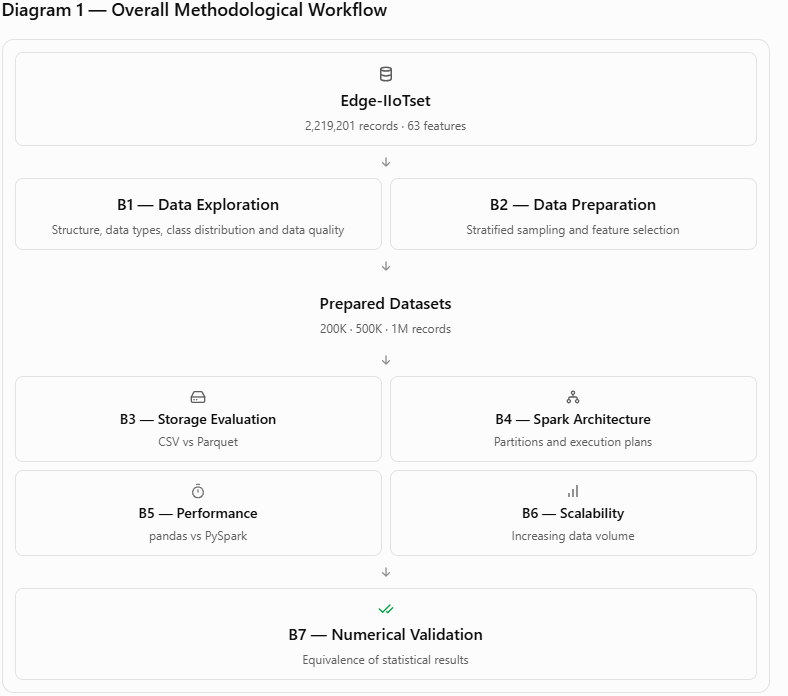


**Figure 1** - The logic is as follows: first, we investigate the characteristics of the data (B1), and then we prepare representative samples (B2). These samples are used to evaluate storage (B3), Spark architecture (B4), performance (B5), and scalability (B6). Finally, we verify the numerical consistency of the calculations (B7).

Figure 1 presents the methodological workflow we adopted to investigate data storage and processing strategies in Industrial Internet of Things (IIoT) environments.

The methodology we propose in this work is structured into seven complementary experiments, labeled B1 through B7, using the Edge-IIoTset dataset, which consists of 2,219,201 records and 63 attributes.

-> Initially, Experiment B1 involved data acquisition, exploration, and characterization, including the identification of attribute types, class distribution, and aspects related to data quality.

-> Next, Experiment B2 focused on data preparation through stratified sampling and the selection of numerical attributes. This step allowed us to construct experimental datasets containing 200,000, 500,000, and 1,000,000 records, which were used in subsequent analyses.

-> The second part of our proposed methodology focused on evaluating storage and processing technologies.

-> Experiment B3 compared CSV and Apache Parquet formats, considering file size as well as read and write times.

-> Experiment B4 investigated the architectural mechanisms of Apache Spark, including partitioning, query optimization, and the execution of aggregation operations.

-> Subsequently, Experiment B5 evaluated the computational performance of pandas and PySpark using equivalent statistical operations. -> Experiment B6 extended this comparison to different data volumes, making it possible to investigate how processing times behave as the number of records increases.

-> Finally, Experiment B7 verified the numerical equivalence of the results produced by the two technologies, using sample means and standard deviations.

The organization shown in Figure 1 illustrates a methodological sequence that links data characterization, technology selection, and result validation, enabling a well-founded assessment of computational efficiency and processing requirements for analytical applications in IIoT.


**2. Diagram 2 — Comparison Between Processing Technologies**

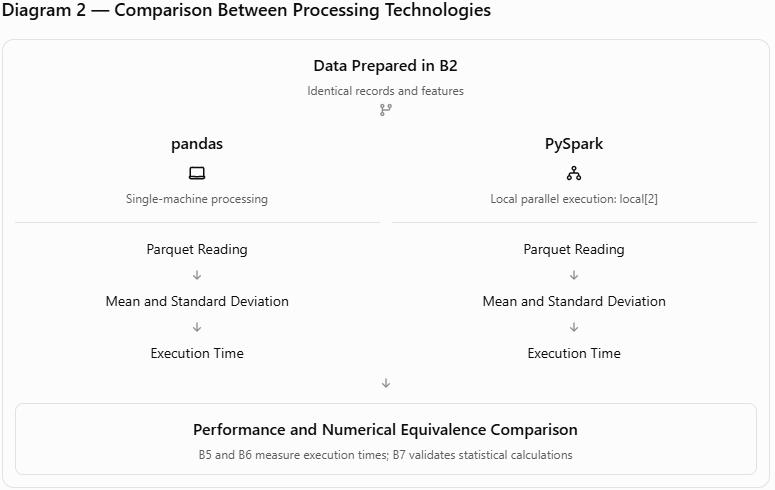


Figure 2 presents the experimental architecture used to compare the computational performance of the pandas and PySpark libraries when processing data from the Edge-IIoTset dataset.

The comparison was conducted using the datasets prepared in Experiment B2, ensuring that both technologies received the same records and numerical attributes.

The experimental procedure was structured into three main operations:

1. Reading Apache Parquet files.
2. Calculating the means and sample standard deviations of the selected attributes, while measuring the time required to execute these operations.

We used pandas as a benchmark for single-machine processing, while PySpark was configured for local parallel execution.

With this setup, we aimed to evaluate the behavior of Spark’s execution engines using local computational resources, without the need to implement a distributed cluster.

In Experiment B5, the two technologies were compared using 200,000 records, which allowed for the identification of differences in execution times under an equivalent workload.

Subsequently, in Experiment B6, we repeated the experiment using datasets containing 200,000, 500,000, and 1,000,000 records, making it possible to assess how an increase in data volume influences computational performance.

To strengthen the validity of the comparison, we developed Experiment B7 to verify whether the statistical results produced by pandas and PySpark were numerically equivalent, accounting for appropriate tolerances for floating-point operations.

Thus, the architecture presented in Figure 2 allows us to investigate not only performance differences but also the consistency of the results produced by the technologies under evaluation.

> It is important to note that the experiments were conducted in a single-machine computational environment. Therefore, the results characterize the local performance of the implementations and should not be interpreted as a direct assessment of the horizontal scalability of Apache Spark in a multi-node cluster.

## B1 — Dataset audit (MLO 1)
Read a small preview to examine the schema. **Do not infer the attack distribution from the first 100,000 rows**: the original CSV may be ordered by class.

### 1 — Identification and Preliminary Selection of Numerical Attributes

Following the initial characterization of the Edge-IIoTset, we conducted a supplementary analysis to identify the available numerical attributes and verify their suitability for storage and processing experiments.

The objective of this step was to establish a consistent set of variables that could be used for equivalent statistical operations across both the pandas and PySpark libraries.

To achieve this, the first 10,000 records from the original file were loaded using the pandas library. This approach allowed us to inspect the data structure without the need to load the entire dataset into memory.

The procedure involved identifying data types, performing a preliminary check for missing values, and automatically selecting columns recognized as numerical.

The variables `Attack_label` and `Attack_type` were excluded from the selection of predictor attributes, as they represent classification information rather than numerical traffic characteristics intended for statistical calculations.

Finally, examples of the selected attributes were presented, allowing for the verification of the selection's consistency prior to the preparation of the experimental datasets.

In [ ]:
preview = pd.read_csv(DATASET_PATH, nrows=10_000, low_memory=False)
print('Preview shape:', preview.shape)
print('Dtypes:', preview.dtypes.value_counts())
print('Missing cells in preview:', int(preview.isna().sum().sum()))
print('Columns:', preview.columns.tolist())
assert {'Attack_label','Attack_type'}.issubset(preview.columns)
feature_cols = preview.select_dtypes(include='number').columns.difference(['Attack_label','Attack_type']).tolist()
print('Numeric features:', len(feature_cols))
print('Feature examples:', feature_cols[:10])
# Prior project used 42 numeric features; confirm this with your specific CSV.

Preview shape: (10000, 63)
Dtypes: float64    49
object     12
int64       2
Name: count, dtype: int64
Missing cells in preview: 0
Columns: ['frame.time', 'ip.src_host', 'ip.dst_host', 'arp.dst.proto_ipv4', 'arp.opcode', 'arp.hw.size', 'arp.src.proto_ipv4', 'icmp.checksum', 'icmp.seq_le', 'icmp.transmit_timestamp', 'icmp.unused', 'http.file_data', 'http.content_length', 'http.request.uri.query', 'http.request.method', 'http.referer', 'http.request.full_uri', 'http.request.version', 'http.response', 'http.tls_port', 'tcp.ack', 'tcp.ack_raw', 'tcp.checksum', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn', 'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack', 'tcp.len', 'tcp.options', 'tcp.payload', 'tcp.seq', 'tcp.srcport', 'udp.port', 'udp.stream', 'udp.time_delta', 'dns.qry.name', 'dns.qry.name.len', 'dns.qry.qu', 'dns.qry.type', 'dns.retransmission', 'dns.retransmit_request', 'dns.retransmit_request_in', 'mqtt.conack.flags', 'mqtt.conflag.cleansess', 

### B1 — Results of the Identification of Numerical Attributes

The preliminary analysis identified the following distribution of data types:

| Data type | Number of columns |
|---|---:|
| `float64` | 49 |
| `int64` | 2 |
| `object` | 12 |
| **Total** | **63** |

The results demonstrate a predominance of numerical attributes, accounting for approximately 81% of the available columns.

The initial check also identified **zero missing cells** across the 10,000 records analyzed. However, this result does not guarantee the absence of invalid or missing values ​​in the complete dataset, as the inspection was limited to the initial sample.

Following the exclusion of classification variables, **50 numerical attributes** were selected for subsequent experiments.

Among the identified attributes are `arp.hw.size`, `arp.opcode`, `dns.qry.name.len`, `dns.qry.type`, and `http.content_length`, which represent characteristics related to communication protocols and network traffic.

The selection of numerical attributes allowed us to establish a suitable structure for performing statistical operations—such as calculating means and standard deviations—which were later used to compare *pandas* and *PySpark*.

Furthermore, the identification of 50 numerical attributes helped standardize the data used in experiments concerning storage, computational performance, scalability, and numerical validation.

## B2 — Representative stratified samples (MLO 1, MLO 3)


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

print("Dataset:", DATASET_PATH)
print("Dataset exists:", Path(DATASET_PATH).is_file())
print("Number of features:", len(feature_cols))
print("Seed:", SEED)

Dataset: /content/data/DNN-EdgeIIoT-dataset.csv
Dataset exists: True
Number of features: 50
Seed: 42


### B2 — Stratified Sampling and Dataset Preparation

Following the initial exploration and identification of the numerical attributes in the Edge-IIoTset, a stratified sampling strategy was implemented to prepare representative datasets for storage and processing experiments.

The need for this approach became apparent during Experiment B1, when it was observed that the first 100,000 records of the original file belonged exclusively to the "normal" traffic class. However, a full analysis of the dataset revealed a distribution of approximately 72.8% normal records and 27.2% malicious records.

This discrepancy highlighted that selecting the initial records sequentially could result in non-representative samples. Therefore, the `Attack_label` variable was used as a stratification criterion, ensuring that the original proportion between the two classes was maintained.

The procedure was implemented via a Python function, `stratified_csv_sample()`, designed to perform sampling without loading the entire CSV file into memory.

The function employs a chunk-based processing strategy, handling blocks of up to 100,000 records. First, the file is scanned to count the number of records belonging to each class. Next, the proportional quotas required to achieve the desired sample size are calculated.

During a second pass through the file, records are randomly selected from each class, using a hypergeometric distribution to control the number of observations chosen from each block. This strategy allows for the creation of a sample of an exact size, while adhering to the established class quotas.

A fixed random seed (`SEED = 42`) was used to ensure the reproducibility of the procedure.

Following the sampling process, the attributes selected in Experiment B1 were converted into numerical formats. Values ​​incompatible with this representation were converted into missing values ​​(`NaN`), as were any infinite values.

The `Attack_label` variable was kept separate as classification information, while the 50 numerical attributes were preserved for subsequent analytical operations.

The procedure initially produced a sample of 1,000,000 records, which served as the basis for generating three experimental datasets:

| Dataset | Records | Numerical attributes | Classification column |
|---|---:|---:|---:|
| Small | 200,000 | 50 | 1 |
| Medium | 500,000 | 50 | 1 |
| Large | 1,000,000 | 50 | 1 |

All three datasets were stored in the Apache Parquet format, allowing them to be reused in subsequent experiments.

Using different volumes of records makes it possible to investigate how an increase in the amount of data influences storage requirements and computational performance.

Furthermore, preparing datasets with an identical attribute structure enables consistent comparisons between pandas and PySpark, reducing methodological differences that could otherwise compromise the interpretation of the results.

In [ ]:
def stratified_csv_sample(path, n_rows, columns=None, label='Attack_label', chunksize=100_000, seed=42):
    """Exact-size stratified sample from a CSV without loading the whole file."""
    rng = np.random.default_rng(seed)
    counts = pd.Series(dtype='int64')
    for chunk in pd.read_csv(path, usecols=[label], chunksize=chunksize, low_memory=False):
        counts = counts.add(chunk[label].value_counts(), fill_value=0)
    counts = counts.astype('int64')
    total = int(counts.sum())
    if n_rows > total: raise ValueError(f'Requested {n_rows:,}, but CSV has {total:,} rows')
    expected = counts * (n_rows / total)
    quotas = np.floor(expected).astype('int64')
    remainder = n_rows - int(quotas.sum())
    for cls in (expected - quotas).sort_values(ascending=False).index[:remainder]:
        quotas.loc[cls] += 1
    remaining_population = counts.to_dict()
    remaining_quota = quotas.to_dict()
    pieces = []
    usecols = list(dict.fromkeys((columns or []) + [label])) if columns is not None else None
    for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize, low_memory=False):
        for cls, group in chunk.groupby(label, sort=False):
            pop = int(remaining_population[cls]); quota = int(remaining_quota[cls]); available = len(group)
            selected = int(rng.hypergeometric(quota, pop-quota, available))
            if selected: pieces.append(group.sample(n=selected, random_state=int(rng.integers(0, 2**32-1))))
            remaining_population[cls] -= available
            remaining_quota[cls] -= selected
    result = pd.concat(pieces, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    assert len(result) == n_rows, (
        f"Expected {n_rows} rows, got {len(result)}"
    )

    assert result[label].notna().all(), (
        "Missing class labels detected"
    )

    print(f"Stratified sample created: {len(result):,} rows")

    return result

In [ ]:
SIZES = [200_000, 500_000, 1_000_000]
source_cols = feature_cols + ['Attack_label']
df_large = stratified_csv_sample(DATASET_PATH, max(SIZES), columns=source_cols, seed=SEED)
for col in feature_cols:
    df_large[col] = pd.to_numeric(df_large[col], errors='coerce').replace([np.inf,-np.inf],np.nan)
df_large['Attack_label'] = pd.to_numeric(df_large['Attack_label'], errors='raise').astype('int64')
print('Large sample:', df_large.shape)
print('Label distribution:', df_large.Attack_label.value_counts(normalize=True).round(4).to_dict())
print('Missing feature cells:', int(df_large[feature_cols].isna().sum().sum()))
paths = {}
for size in SIZES:
    path = OUT / f'iiot_numeric_{size}.parquet'
    df_large.iloc[:size].to_parquet(path,index=False)
    paths[size] = path
    print(size, 'Parquet MB:', round(path.stat().st_size/2**20,2))

Stratified sample created: 1,000,000 rows
Large sample: (1000000, 51)
Label distribution: {0: 0.728, 1: 0.272}
Missing feature cells: 70750
200000 Parquet MB: 4.7
500000 Parquet MB: 10.59
1000000 Parquet MB: 20.3


### B2 — Stratified Sampling Results and Data Preparation

The execution of the stratified sampling procedure yielded a sample of **1,000,000 records and 51 columns**, consisting of 50 numerical attributes and the binary classification variable `Attack_label`.

The resulting class distribution was as follows:

| Classification | Proportion | Approximate Records |
|---|---:|---:|
| Normal traffic (0) | 72.8% | 728,000 |
| Malicious traffic (1) | 27.2% | 272,000 |
| **Total** | **100%** | **1,000,000** |

The results demonstrate that the sampling process successfully preserved the binary distribution found in the original dataset.

This consistency is significant, as it allows for the use of representative subsets in subsequent analyses—thereby avoiding the issue encountered during the initial exploration, where the first 100,000 records consisted exclusively of normal traffic.

During the conversion of the numerical attributes, **70,750 cells with missing values ​​(`NaN`)** were identified within the 1,000,000-record sample.

This finding contrasts with the preliminary inspection in B1, which did not identify any missing cells in the first 10,000 records. This discrepancy highlights the importance of assessing data quality beyond just the initial observations in a file.

The missing values ​​were left as-is at this stage, as subsequent statistical aggregation experiments utilize operations capable of excluding them. This approach also avoids the introduction of artificial values ​​through imputation prior to benchmarking.

Following the preparation phase, three Apache Parquet files were generated, as shown in Table B2.1. **Table B2.1 — Dimensions and sizes of the experimental datasets**

| Records | Columns | Size in Parquet |
|---|---:|---:|
| 200,000 | 51 | 4.70 MiB |
| 500,000 | 51 | 10.59 MiB |
| 1,000,000 | 51 | 20.30 MiB |

The results demonstrate that the prepared files are relatively small in size, even while containing hundreds of thousands of records.

This characteristic is due to the numerical representation of the attributes, as well as the encoding and compression mechanisms employed by the Apache Parquet format.

However, a quantitative assessment of the benefits of this format compared to CSV will be conducted specifically in Experiment B3.

The generated datasets also feature progressively larger volumes, which allows for the investigation of how processing technologies behave as the number of records increases.

It is important to note that the datasets containing 200,000 and 500,000 records were derived from the first rows of the 1,000,000-record sample, which had been previously shuffled. Therefore, these are nested subsets rather than three independent, stratified samples.

Although the main sample preserves the original binary distribution, the exact class proportions within the smaller subsets should be verified individually if a specific comparison of representativeness is required.

Overall, Experiment B2 achieved its objective of producing structured datasets with defined sizes and consistent attributes, establishing the necessary conditions for experiments concerning storage, architecture, performance, scalability, and numerical validation.

The code performs two passes over the original CSV file, avoiding the need to load all 2.2 million records into memory simultaneously.

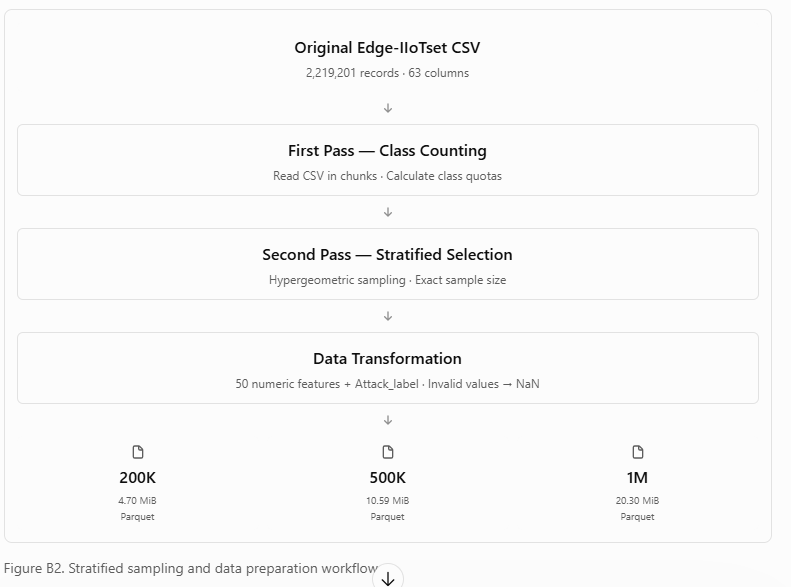


There are three points worth clarifying in the report:
- **Stratified sampling**: We preserve the proportions of the `Attack_label` classes, but not necessarily the individual proportions of the 14 `Attack_type` categories.
- **Missing values**: The 70,750 NaN cells represent missing values ​​resulting from the numerical conversion; they do not necessarily correspond to values ​​that were already missing in the original CSV file.
- **Chunk-based processing**: Reading the data in chunks reduces the need to load the entire file, but the function still aggregates the selected sample into memory. Therefore, this is not a fully "out-of-core" processing solution.

## B3 — Storage experiment: CSV versus Parquet (MLO 1)
For a fair comparison, serialize **the same 200k rows and same columns** to CSV and Parquet. Measure file size and repeated read time; serialization time is recorded separately.

### B3 — Evaluation of Storage Efficiency: CSV versus Apache Parquet

Following the preparation of the datasets in Experiment B2, a comparative evaluation of the CSV (*Comma-Separated Values*) and Apache Parquet formats was conducted to investigate the impact of the storage structure on disk space usage and the performance of data input/output (I/O) operations.

CSV is a text-based format widely used for storing and exchanging tabular data. Its primary advantages are its simplicity, portability, and compatibility with a variety of tools. However, its textual representation can increase the storage space required for numerical values ​​and necessitate additional interpretation and conversion operations during data retrieval.

Apache Parquet, conversely, employs columnar storage, organizing values ​​according to the table's attributes. This structure facilitates encoding and compression mechanisms, while also allowing analytical tools to retrieve only the specific columns required for a given operation. Due to these characteristics, Parquet is frequently used in architectures designed for the analytical processing of large volumes of data (Apache Parquet, n.d.).

To compare the two formats, the dataset—consisting of **200,000 records and 51 columns** (50 numerical attributes plus the classification variable `Attack_label`)—prepared in Experiment B2 was used.

The evaluation was carried out using the `pandas` library and structured around three criteria:

1. **Storage space:** measurement of the file size for both CSV and Parquet formats, expressed in MiB.
2. **Write time:** measurement of the time required to save the same dataset in each format.
3. **Read time:** measurement of the time required to load the files, based on five timed runs following an initial "warm-up" read. Measurements were performed using the `time.perf_counter()` function, which is suitable for timing execution intervals with a high-resolution clock.

For read times, the mean and standard deviation across five runs were calculated, allowing for an assessment of both average performance and observed variability.

The results were organized into a DataFrame and exported to a CSV file, facilitating their subsequent use in a comparative analysis.

It is important to note that this experiment evaluates read and write operations performed using pandas within the Google Colab environment. Therefore, the results do not represent a direct comparison between distributed storage mechanisms, but rather an experimental evaluation of file formats under local conditions.

In [ ]:
import pandas as pd
import time
from pathlib import Path

OUT = Path("/content/iiot_ca_results")

parquet_path = OUT / "iiot_numeric_200000.parquet"

assert parquet_path.is_file(), (
    f"Arquivo não encontrado: {parquet_path}"
)

sample_200k = pd.read_parquet(parquet_path)

print("Dataset recuperado com sucesso!")
print("Dimensões:", sample_200k.shape)
print("Tamanho:", round(parquet_path.stat().st_size / 2**20, 2), "MB")

Dataset recuperado com sucesso!
Dimensões: (200000, 51)
Tamanho: 4.7 MB


In [ ]:

# B3 — CSV vs Parquet Storage Benchmark
# Big Data Storage and Processing — MLO 1

import time
import pandas as pd

csv_path = OUT / "iiot_numeric_200000.csv"
parquet_path = OUT / "iiot_numeric_200000.parquet"

# Measure CSV writing time
start = time.perf_counter()
sample_200k.to_csv(csv_path, index=False)
csv_write = time.perf_counter() - start

# Measure Parquet writing time
start = time.perf_counter()
sample_200k.to_parquet(parquet_path, index=False)
parquet_write = time.perf_counter() - start

storage_results = []

formats = [
    ("CSV", csv_path, csv_write, pd.read_csv),
    ("Parquet", parquet_path, parquet_write, pd.read_parquet)
]

for fmt, path, writer_time, reader in formats:

    # Warm-up
    _ = reader(path)

    for run in range(1, 6):
        start = time.perf_counter()
        loaded = reader(path)
        elapsed = time.perf_counter() - start

        storage_results.append({
            "Format": fmt,
            "Run": run,
            "Rows": len(loaded),
            "Columns": len(loaded.columns),
            "File_MB": path.stat().st_size / 2**20,
            "Write_Seconds": writer_time,
            "Read_Seconds": elapsed
        })

storage_df = pd.DataFrame(storage_results)

summary = storage_df.groupby("Format").agg(
    File_MB=("File_MB", "first"),
    Write_Seconds=("Write_Seconds", "first"),
    Mean_Read_Seconds=("Read_Seconds", "mean"),
    Std_Read_Seconds=("Read_Seconds", "std")
).round(4)

display(summary)

storage_df.to_csv(
    OUT / "storage_csv_vs_parquet.csv",
    index=False
)

print("Experiment B3 completed successfully!")


,File_MB,Write_Seconds,Mean_Read_Seconds,Std_Read_Seconds
Format,,,,
CSV,42.4660,7.7042,1.2730,0.2875
Parquet,4.6964,0.6444,0.1796,0.0649


Experiment B3 completed successfully!


### B3 — Results of the Comparison between CSV and Apache Parquet

The execution of Experiment B3 allowed for a comparison of storage space as well as read and write times between the CSV and Apache Parquet formats, using the same dataset consisting of 200,000 records and 51 columns.

Table B3.1 presents the results obtained.

**Table B3.1 — Storage and performance comparison between CSV and Parquet**

| Metric | CSV | Apache Parquet |
|---|---:|---:|
| File size (MiB) | 42.4660 | 4.6964 |
| Write time (s) | 7.7042 | 0.6444 |
| Average read time (s) | 1.2730 | 0.1796 |
| Standard deviation of read time (s) | 0.2875 | 0.0649 |

The results demonstrate that the Apache Parquet format required less storage space and yielded faster read and write times under the evaluated conditions.


1. **Storage efficiency**


The CSV file occupied approximately 42.47 MiB, while the Parquet file occupied 4.70 MiB, representing a reduction of approximately **88.94% in storage space used**.

This difference can be attributed to the textual representation of values ​​in CSV, compared to the encoding and compression mechanisms employed by the columnar Parquet format.


2. **Write performance**

The write time for the CSV format was 7.7042 seconds, whereas the Parquet format took 0.6444 seconds.

In this experiment, writing data in the Parquet format was approximately **11 times faster** than writing in the CSV format.

This result highlights an advantage of the Parquet format under the tested conditions. However, since only one write measurement was performed for each format, it is not possible to statistically evaluate the variability of these times.

3. **Reading performance**

The CSV format showed an average read time of 1.2730 seconds, while the Parquet format showed 0.1796 seconds.

Thus, reading the Parquet file was approximately **7 times faster**.

The standard deviation was also lower for Parquet, indicating less absolute variation in read times across the five observed runs.

> However, since the read operations were performed after a "warm-up" phase, the results may have been influenced by the operating system's cache and the transient conditions of the Google Colab environment.

3. **Interpretation of results**

Overall, the results indicate that Apache Parquet was more efficient than CSV for storing and retrieving the numerical dataset used in this experiment.

Reducing file size can help lower storage and data transfer requirements, while faster read times can benefit repetitive analytical operations.

These characteristics justify the use of Parquet in subsequent experiments involving pandas and PySpark, allowing both technologies to work with a consistent data representation.

It is important to note that these results do not imply that Parquet will necessarily be superior in every scenario. Performance depends on factors such as data types, compression, hardware, the specific library used, and the characteristics of the workload.

Therefore, Experiment B3 provides evidence that—given the numerical dataset selected for this experiment and the specific computing environment evaluated—Apache Parquet offered advantages in terms of both storage and performance compared to CSV.

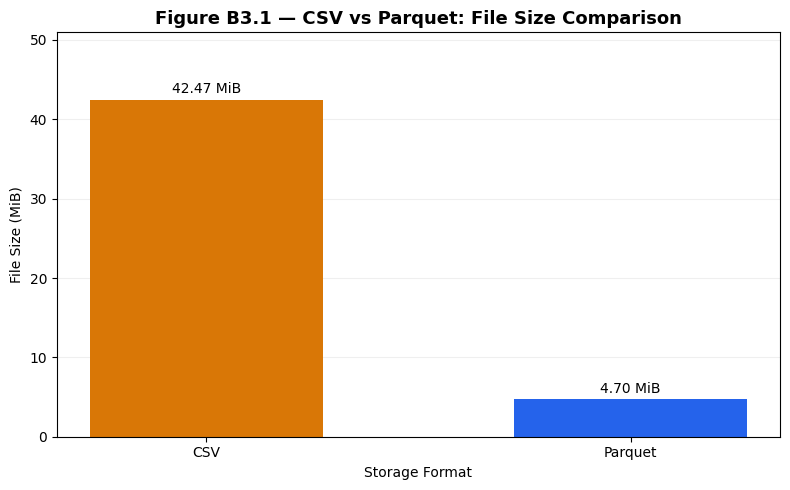

In [ ]:

fig, ax = plt.subplots(figsize=(8, 5))

formats = b3_results.index.tolist()
sizes = b3_results["File_MB"].values

bars = ax.bar(
    formats,
    sizes,
    color=["#D97706", "#2563EB"],
    width=0.55
)

ax.set_title(
    "Figure B3.1 — CSV vs Parquet: File Size Comparison",
    fontsize=13,
    fontweight="bold"
)
ax.set_ylabel("File Size (MiB)")
ax.set_xlabel("Storage Format")
ax.set_ylim(0, max(sizes) * 1.2)

for bar, value in zip(bars, sizes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(sizes) * 0.02,
        f"{value:.2f} MiB",
        ha="center"
    )

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "/content/iiot_ca_results/B3_file_size_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


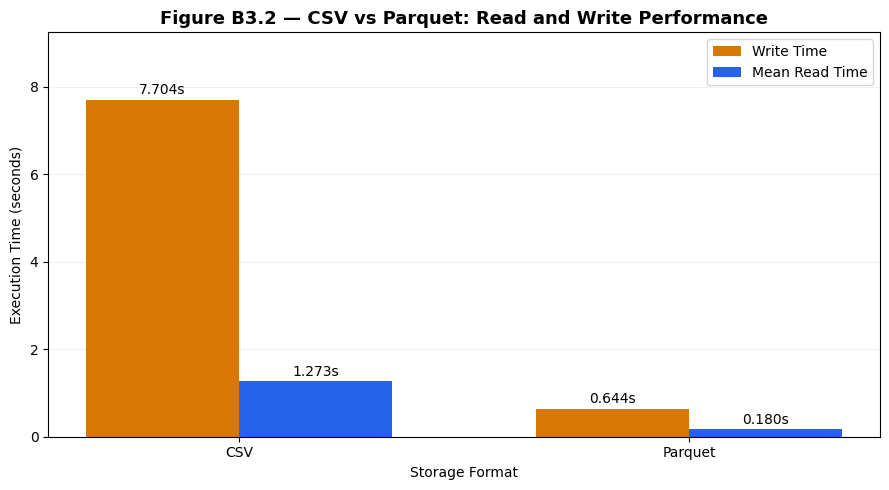

In [ ]:

fig, ax = plt.subplots(figsize=(9, 5))

formats = b3_results.index.tolist()

write_times = b3_results["Write_Seconds"].values
read_times = b3_results["Mean_Read_Seconds"].values

x = np.arange(len(formats))
width = 0.34

bars_write = ax.bar(
    x - width / 2,
    write_times,
    width,
    label="Write Time",
    color="#D97706"
)

bars_read = ax.bar(
    x + width / 2,
    read_times,
    width,
    label="Mean Read Time",
    color="#2563EB"
)

ax.set_title(
    "Figure B3.2 — CSV vs Parquet: Read and Write Performance",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Storage Format")
ax.set_ylabel("Execution Time (seconds)")
ax.set_xticks(x)
ax.set_xticklabels(formats)
ax.legend()

ax.set_ylim(
    0,
    max(max(write_times), max(read_times)) * 1.2
)

for bars in [bars_write, bars_read]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.12,
            f"{bar.get_height():.3f}s",
            ha="center",
            fontsize=10
        )

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "/content/iiot_ca_results/B3_read_write_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### B3 — Comparative Visualization of Results

Figure B3.1 provides a comparison of the storage space required to represent the same dataset in CSV and Apache Parquet formats. The results demonstrate an approximate 88.94% reduction in file size when using Parquet.

Figure B3.2 displays the read and write times for both formats. An analysis of the chart reveals that Parquet performed better in both operations, with shorter processing times than those recorded for CSV.

These results provide experimental evidence supporting the selection of the Apache Parquet format for subsequent processing and scalability experiments.

## B4 — Spark architecture inspection (MLO 2)

> Add blockquote


The Spark driver coordinates tasks; local executors use the Colab machine. Inspect the logical/physical execution plan and partitions. This is an **architecture demonstration**, not evidence of multi-node scalability.

In [ ]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("IIoT_BigData_CA")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

spark.range(5).show()

+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



### B4 — Analysis of Apache Spark Architecture and Execution Plans

Following the evaluation of storage formats in Experiment B3, an investigation into Apache Spark’s processing mechanisms was conducted to understand how the framework organizes and executes analytical operations on structured data.

Apache Spark is a data processing engine that supports parallel and distributed execution. Its architecture allows for the division of operations into tasks, the processing of data partitions, and the combination of results through aggregation and inter-process communication mechanisms (Zaharia et al., 2016).

A key feature of Spark is the use of Spark SQL, which enables operations on structured data via the DataFrame API. Spark SQL incorporates query optimization and execution plan selection mechanisms, which help reduce unnecessary operations and organize processing efficiently (Armbrust et al., 2015).

In this experiment, a dataset containing **200,000 records and 51 columns**—previously prepared in the Apache Parquet format—was used.

The Spark environment was configured in Google Colab using the `local[2]` parallel execution mode, which provides two execution threads for processing tasks.

The experimental procedure involved reading the Parquet file, identifying the number of partitions, and performing a statistical aggregation operation.

For this analysis, records were grouped by the `Attack_label` variable, and the mean of the numerical attribute `tcp.ack` was calculated for each class.

This operation served as an example of analytical processing, allowing for an observation of how Spark organizes a query that involves reading, grouping, and aggregating data.

The `explain(True)` function was used to display the execution plans generated by Spark, including:

- **Parsed Logical Plan:** the initial representation of the requested query. - **Analyzed Logical Plan:** validation of the attributes and operations used.
- **Optimized Logical Plan:** application of optimizations to the query.
- **Physical Plan:** definition of the physical operations used to carry out the processing.

Analyzing these plans makes it possible to identify mechanisms such as column projection, partial aggregation, data redistribution (*shuffle*), and adaptive query execution.

It is important to note that the experiment was conducted on a single machine, utilizing local parallelism. Therefore, although Spark features an architecture capable of operating on distributed clusters, the procedure developed does not represent an experimental evaluation of multi-node processing.

The primary objective of B4 is to understand and document the architectural mechanisms of Spark that will subsequently be considered when interpreting performance and scalability results.

In [ ]:
from pyspark.sql import functions as F

sdf = spark.read.parquet(
    "/content/iiot_ca_results/iiot_numeric_200000.parquet"
)

print("Spark master:", spark.sparkContext.master)
print("Partitions:", sdf.rdd.getNumPartitions())
print("Records:", sdf.count())

feature = "tcp.ack"

if feature not in sdf.columns:
    feature = next(
        col for col in sdf.columns
        if col != "Attack_label"
    )

result = sdf.groupBy("Attack_label").agg(
    F.avg(F.col(f"`{feature}`")).alias("feature_mean")
)

result.explain(True)
result.show()

Spark master: local[2]
Partitions: 2
Records: 200000
== Parsed Logical Plan ==
'Aggregate ['Attack_label], ['Attack_label, 'avg('`tcp.ack`) AS feature_mean#291]
+- Relation [arp.opcode#185,arp.hw.size#186,icmp.checksum#187,icmp.seq_le#188,icmp.transmit_timestamp#189,icmp.unused#190,http.file_data#191,http.content_length#192,http.request.uri.query#193,http.request.method#194,http.referer#195,http.request.full_uri#196,http.request.version#197,http.response#198,http.tls_port#199,tcp.ack#200,tcp.ack_raw#201,tcp.checksum#202,tcp.connection.fin#203,tcp.connection.rst#204,tcp.connection.syn#205,tcp.connection.synack#206,tcp.dstport#207,tcp.flags#208,tcp.flags.ack#209,... 26 more fields] parquet

== Analyzed Logical Plan ==
Attack_label: bigint, feature_mean: double
Aggregate [Attack_label#235L], [Attack_label#235L, avg(tcp.ack#200) AS feature_mean#291]
+- Relation [arp.opcode#185,arp.hw.size#186,icmp.checksum#187,icmp.seq_le#188,icmp.transmit_timestamp#189,icmp.unused#190,http.file_data#191,h

### B4 — Results of the Apache Spark Architectural Analysis

The execution of experiment B4 confirmed the reading and processing of the dataset prepared in Experiment B2.

The key results from the environment configuration and inspection were:

**Table B4.1 — Apache Spark execution characteristics**

| Parameter | Result |
|---|---|
| Execution mode | `local[2]` |
| Number of input partitions | 2 |
| Records processed | 200,000 |
| Storage format | Apache Parquet |
| Analytical operation | Average grouped by `Attack_label` |
| Analyzed attribute | `tcp.ack` |

The `local[2]` configuration indicates that Spark was executed on a single machine, with the capacity to use two threads for the parallel execution of tasks.

The identification of two partitions demonstrates that the DataFrame was organized into processing units that can be distributed among Spark tasks.

However, the number of partitions should not be interpreted as the number of machines or nodes in a cluster.

1. **Analysis of execution plans**

Executing the `explain(True)` function provided both the logical and physical representations of the query.

In the optimized logical plan, a `Project` operation was identified, which is responsible for selecting the attributes required for processing.

In the physical plan, the following mechanisms were observed:

| Operation | Function in processing |
|---|---|
| `FileScan parquet` | Reading data stored in Parquet format |
| `HashAggregate` | Calculation of statistical aggregations |
| `partial_avg` | Partial calculation of the average |
| `Exchange hashpartitioning` | Redistribution of data based on the grouping key |
| `AdaptiveSparkPlan` | Structure used for adaptive query execution | The physical plan demonstrated that the Parquet file read only used the `tcp.ack` and `Attack_label` columns, even though the original prepared file contained 51 columns.

This behavior characterizes the optimization known as column pruning, in which attributes unnecessary to the query are excluded from the read.

The use of `partial_avg` indicates that Spark performed partial aggregations before the data redistribution step. Subsequently, the `Exchange hashpartitioning` operation organized the results by class, allowing the combination of aggregations.

The plan also presented `AdaptiveSparkPlan isFinalPlan=false`, indicating that the query was represented by an adaptive plan that was not yet finalized at the time of inspection. This information demonstrates the presence of the adaptive execution mechanism, but does not, in isolation, prove that a specific adaptive optimization was applied.

2. **Results of Statistical Aggregation**

The grouping operation by `Attack_label` yielded the following approximate results:

| Class | Average of `tcp.ack` |

|---|---:|

| 0 — Normal traffic | 536,278.99 |

| 1 — Malicious traffic | 7,047,534.61 |

The results demonstrate differences between the averages of the `tcp.ack` attribute for the two classes.

However, this difference is not sufficient to conclude that the attribute, in isolation, is capable of identifying cyberattacks. An evaluation of this hypothesis would require further analysis of the distribution of values and their discriminatory capacity.

In this experiment, aggregation was used primarily to investigate the internal execution mechanisms of Spark, and not to select predictive attributes.

3. **Discussion of results**

The results from B4 demonstrate that Apache Spark organizes processing through specialized physical operations, including selective column reading, partial aggregations, and data redistribution.

These mechanisms are relevant to analytical processing because they allow for the organization of parallel tasks and a reduction in the volume of data handled during specific stages.

On the other hand, operations such as `Exchange` can introduce additional processing, communication, and synchronization costs, depending on the environment configuration and the characteristics of the query.

Thus, B4 provides an architectural foundation for interpreting subsequent experiments, in which Spark’s performance will be compared with that of pandas.

Although the observed mechanisms are compatible with distributed architectures, the results obtained specifically characterize local parallel execution within Google Colab.

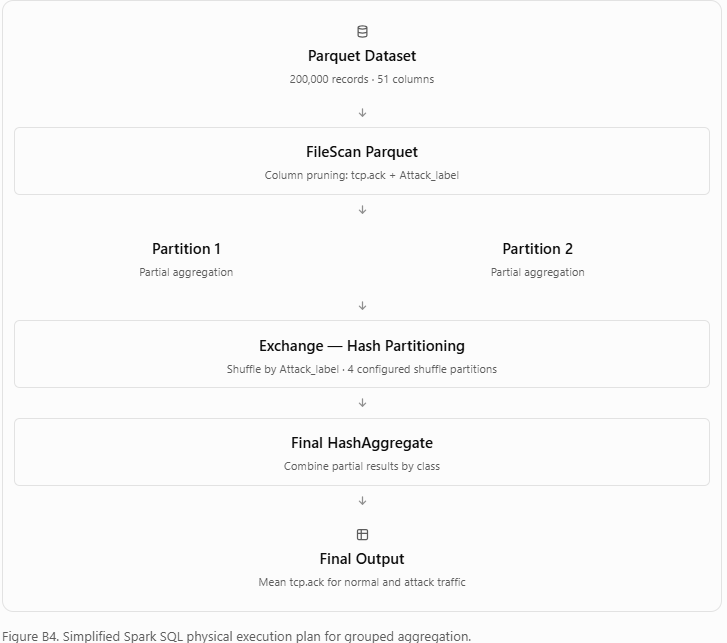

O diagrama representa as operações observadas no plano físico. As duas partições indicadas correspondem às partições de entrada; as quatro partições de shuffle representam a configuração de redistribuição mostrada no plano, não quatro máquinas de processamento.

## B5 — Equivalent numerical statistics: pandas vs PySpark (MLO 3)
Both frameworks calculate **feature means and sample standard deviations**. Quote dotted column names in Spark using backticks. Verify numerical equivalence before timing.

In [ ]:

# Restore dataset paths after kernel restart

from pathlib import Path

OUT = Path("/content/iiot_ca_results")

SIZES = [200_000, 500_000, 1_000_000]

paths = {
    size: OUT / f"iiot_numeric_{size}.parquet"
    for size in SIZES
}

print("Available datasets:")

for size, path in paths.items():
    print(
        f"{size:,} records:",
        "FOUND" if path.is_file() else "NOT FOUND",
        "|",
        path
    )

assert paths[200_000].is_file(), (
    "The 200k Parquet dataset was not found."
)

print("\nDataset paths restored successfully!")


Available datasets:
200,000 records: FOUND | /content/iiot_ca_results/iiot_numeric_200000.parquet
500,000 records: FOUND | /content/iiot_ca_results/iiot_numeric_500000.parquet
1,000,000 records: FOUND | /content/iiot_ca_results/iiot_numeric_1000000.parquet

Dataset paths restored successfully!


In [ ]:

# ==================================================
# BIG DATA CA — NOTEBOOK CONFIGURATION
# ==================================================

import os
import time
import numpy as np
import pandas as pd

from pathlib import Path
from pyspark.sql import SparkSession, functions as F

SEED = 42

OUT = Path("/content/iiot_ca_results")
OUT.mkdir(parents=True, exist_ok=True)

SIZES = [200_000, 500_000, 1_000_000]

paths = {
    size: OUT / f"iiot_numeric_{size}.parquet"
    for size in SIZES
}

print("Environment configured successfully!")

for size, path in paths.items():
    print(f"{size:,} records: {path.is_file()}")


Environment configured successfully!
200,000 records: True
500,000 records: True
1,000,000 records: True


### B5 — Comparative Evaluation of Computational Performance: pandas vs. PySpark

To evaluate the computational performance of the pandas and PySpark libraries in executing statistical operations, we developed a comparative benchmark.

The primary objective of this experiment is to investigate the differences in processing time between an in-memory data analysis library—represented here by pandas—and a parallel processing engine, represented by Apache Spark via its PySpark interface.

pandas provides data structures and vectorized operations well-suited for the manipulation and analysis of tabular data. Its architecture allows for the efficient execution of statistical operations, provided that the data can be processed within the available memory resources (McKinney, 2010).

Apache Spark, by contrast, utilizes an architecture based on dividing processing into tasks and partitions. This approach enables parallel execution and the distribution of workloads across various computational resources. However, executing such tasks also entails overhead related to planning, coordination, and the aggregation of results (Zaharia et al., 2016).

Consequently, employing a framework designed for distributed processing does not automatically guarantee shorter execution times—particularly when the data volume is relatively small and can be processed entirely in-memory.

**Experimental Methodology**

For this comparison, we used the dataset prepared in Experiment B2, which contains 200,000 records and 51 columns, stored in the Apache Parquet format.

Of these columns, 50 are numerical attributes used in the statistical operations. The `Attack_label` variable was excluded from the calculations, as it represents the classification of the records.

Two independent functions were implemented:

- `pandas_processing()`: reads the Parquet file and calculates the means and sample standard deviations for the 50 numerical attributes using pandas. - `spark_processing()`: reads the same file and performs equivalent statistical operations using PySpark’s aggregation functions.

To ensure comparability, both implementations used the same records, attributes, and storage format.

PySpark was executed in local parallel mode (`local[2]`) on a single machine within a Google Colab environment.

Before taking measurements, an initial "warm-up" run of each function was performed to mitigate effects related to initialization and the first execution.

Subsequently, five timed runs were conducted for each technology using the `time.perf_counter()` function.

The recorded time included both the reading of the Parquet file and the calculation of the statistics. For Spark, the `collect()` operation was used to materialize the aggregation result and complete the execution before the measurement ended.

Finally, the individual run times were stored in a DataFrame and used to calculate the average execution time for each technology.

The results were exported to a file named `pandas_vs_spark_200k.csv` for use in further analysis and visualization.

The experiment was designed to compare the performance of these technologies under an equivalent workload, rather than to demonstrate the universal superiority of one implementation over the other.

Since Spark was run in local mode, the results reflect performance within that specific environment and do not constitute an evaluation of distributed processing on a multi-node cluster.

Reference

1. McKinney, W. (2010) 'Data Structures for Statistical Computing in Python', Proceedings of the 9th Python in Science Conference, pp. 56–61. https://doi.org/10.25080/Majora-92bf1922-00a

2. Zaharia, M., Xin, R.S., Wendell, P., Das, T., Armbrust, M., Dave, A., Meng, X., Rosen, J., Venkataraman, S., Franklin, M.J., Ghodsi, A., Gonzalez, J., Shenker, S. and Stoica, I. (2016) 'Apache Spark: A Unified Engine for Big Data Processing', Communications of the ACM, 59(11), pp. 56–65. https://doi.org/10.1145/2934664

## Next step: execute B5 — Pandas vs PySpark

In [ ]:
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
spark.range(5).show()

Spark version: 4.0.4
Spark master: local[2]
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



In [ ]:

# B5 — Pandas vs PySpark Processing Benchmark
# Big Data Storage and Processing — MLO 3

import time
import pandas as pd
import numpy as np
from pyspark.sql import functions as F

parquet_path = paths[200_000]

feature_cols = [
    col for col in pd.read_parquet(parquet_path).columns
    if col != "Attack_label"
]

print("Number of features:", len(feature_cols))

def pandas_processing(path):
    df = pd.read_parquet(path)

    means = df[feature_cols].mean()
    stds = df[feature_cols].std()

    return means, stds

def spark_processing(path):
    df = spark.read.parquet(str(path))

    expressions = []

    for col in feature_cols:
        safe_col = F.col("`" + col.replace("`", "``") + "`")

        expressions.append(
            F.avg(safe_col).alias(col + "_mean")
        )

        expressions.append(
            F.stddev_samp(safe_col).alias(col + "_std")
        )

    return df.agg(*expressions).collect()[0]

results = []

# Warm-up
pandas_processing(parquet_path)
spark_processing(parquet_path)

for run in range(1, 6):

    start = time.perf_counter()
    pandas_processing(parquet_path)
    pandas_time = time.perf_counter() - start

    start = time.perf_counter()
    spark_processing(parquet_path)
    spark_time = time.perf_counter() - start

    results.append({
        "Run": run,
        "Pandas_Seconds": pandas_time,
        "PySpark_Seconds": spark_time
    })

benchmark_df = pd.DataFrame(results)

display(benchmark_df)

print("\nAverage execution times:")
print(
    benchmark_df[
        ["Pandas_Seconds", "PySpark_Seconds"]
    ].mean().round(4)
)

benchmark_df.to_csv(
    OUT / "pandas_vs_spark_200k.csv",
    index=False
)

print("\nExperiment B5 completed successfully!")


Number of features: 50


,Run,Pandas_Seconds,PySpark_Seconds
0,1,0.901330,6.223816
1,2,0.486066,7.033498
2,3,0.813768,4.135276
3,4,0.374286,4.008407
4,5,0.337064,5.471145



Average execution times:
Pandas_Seconds     0.5825
PySpark_Seconds    5.3744
dtype: float64

Experiment B5 completed successfully!


### B5 — Performance Comparison Results: pandas vs. PySpark

Conducting Experiment B5 allowed us to measure the time required to perform equivalent statistical operations using both pandas and PySpark on a dataset consisting of 200,000 records and 50 numerical attributes.

Table B5.1 shows the execution times recorded across five separate runs.

**Table B5.1 — Execution times for pandas and PySpark**

| Run | pandas (s) | PySpark (s) |
|---|---:|---:|
| 1 | 0.901330 | 6.223816 |
| 2 | 0.486066 | 7.033498 |
| 3 | 0.813768 | 4.135276 |
| 4 | 0.374286 | 4.008407 |
| 5 | 0.337064 | 5.471145 |
| **Average** | **0.5825** | **5.3744** |

The results demonstrate that pandas yielded shorter execution times in all five measurements.

The average time recorded for pandas was approximately 0.5825 seconds, while PySpark showed an average of 5.3744 seconds.

Consequently, **pandas was approximately 9 times faster than PySpark** in the experiments conducted.

**Analysis of pandas performance**

In every measurement, pandas achieved execution times of less than one second, demonstrating efficiency in processing the selected numerical dataset.

This behavior is consistent with its intended use for analytical operations on data that can be processed within the memory resources of a single machine. Performing statistical operations directly—without the overhead of organizing tasks through Spark’s execution engine—can help reduce total processing time.

**PySpark Performance Analysis**

PySpark recorded longer execution times than pandas, ranging approximately between 4.01 and 7.03 seconds.

Although Apache Spark employs parallel execution mechanisms, its processing involves additional steps, such as planning, task orchestration, and aggregating results.

For a dataset of 200,000 records, these overheads can account for a significant portion of the total execution time.

It is important to note that this result does not indicate a fundamental limitation of Spark; rather, it highlights that the use of parallelism does not guarantee performance gains at every scale of data.

**Discussion of Results**

The observed difference between these technologies underscores the importance of selecting processing tools based on data volume and the specific nature of the operations being performed.

For the dataset of 200,000 records, pandas proved more time-efficient under the experimental conditions evaluated.

Conversely, Apache Spark provides architectural mechanisms—such as parallelism, partitioning, and distributed processing—that can be highly advantageous in scenarios involving larger data volumes or requirements for horizontal scalability.

> It should be noted, however, that these capabilities were not explicitly tested within a distributed cluster in this experiment.

Furthermore, since the five runs were executed sequentially within the same Google Colab environment, the results may have been influenced by factors such as caching, the availability of computational resources, and variations in task execution.

Therefore, Experiment B5 provides evidence that pandas performed better for a workload of 200,000 records, while a more in-depth investigation into how these technologies behave across different data volumes will be conducted in Experiment B6.

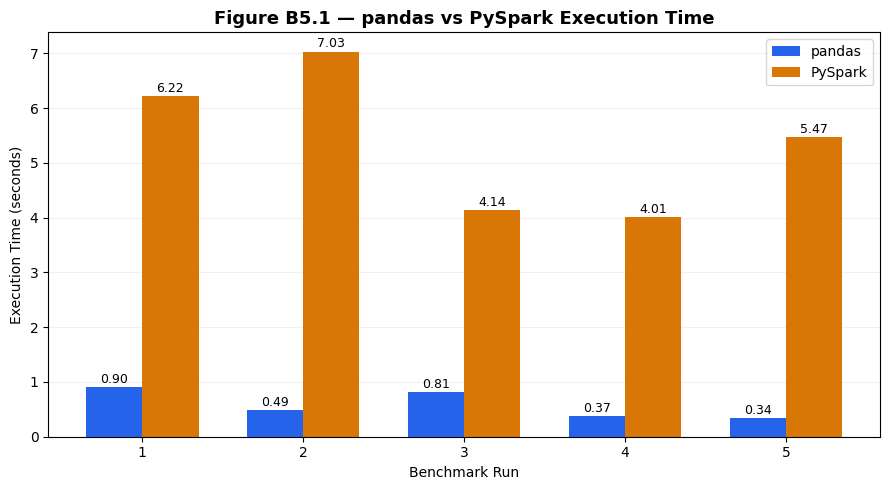

Figure saved to: /content/iiot_ca_results/B5_pandas_vs_pyspark.png


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load B5 results from the saved file
result_path = Path(
    "/content/iiot_ca_results/pandas_vs_spark_200k.csv"
)

b5_results = pd.read_csv(result_path)

x = np.arange(len(b5_results))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_pandas = ax.bar(
    x - width / 2,
    b5_results["Pandas_Seconds"],
    width,
    label="pandas",
    color="#2563EB"
)

bars_spark = ax.bar(
    x + width / 2,
    b5_results["PySpark_Seconds"],
    width,
    label="PySpark",
    color="#D97706"
)

ax.set_title(
    "Figure B5.1 — pandas vs PySpark Execution Time",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Benchmark Run")
ax.set_ylabel("Execution Time (seconds)")

ax.set_xticks(x)
ax.set_xticklabels(b5_results["Run"])

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for bars in [bars_pandas, bars_spark]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.08,
            f"{bar.get_height():.2f}",
            ha="center",
            fontsize=9
        )

plt.tight_layout()

output_path = Path(
    "/content/iiot_ca_results/B5_pandas_vs_pyspark.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", output_path)


### B5 — Graphical Analysis of Execution Times

Figure B5.1 presents the execution times recorded during five repetitions of a comparative benchmark between pandas and PySpark, using a dataset of 200,000 records and 50 numerical attributes.

The results demonstrate that pandas yielded shorter processing times than PySpark in all conducted runs.

Pandas recorded an average execution time of approximately 0.5825 seconds, while PySpark showed an average of 5.3744 seconds—a performance difference of approximately 9.23 times in favor of pandas.

Variations in execution times were also observed for both technologies, likely related to the conditions of the computing environment, memory management, and internal processing mechanisms.

The observed difference may be attributed to the overhead associated with task planning and coordination in Apache Spark, which can account for a significant portion of the total time when dealing with relatively small datasets.

These results suggest that pandas is an efficient alternative for statistical operations on datasets that can be processed entirely in-memory.

This evaluation will be expanded in Experiment B6, which will utilize varying volumes of records to investigate how these technologies perform as the processing load increases.

## B6 — Scalability experiment: 200k, 500k, 1M × 42 features (MLO 3)



### B6 — Evaluation of Computational Scalability: pandas versus PySpark


Computational scalability refers to a system's ability to handle increasing workloads while maintaining acceptable performance. In systems designed for processing large volumes of data, this characteristic is crucial for assessing the efficiency of technologies as the amount of stored and processed information grows.

Apache Spark was developed to support parallel and distributed processing, utilizing partitioning mechanisms and task execution strategies that allow for the organization of analytical operations on large datasets (Zaharia et al., 2016).

However, the performance of a parallel system depends on factors such as data volume, the nature of the operations, available computational resources, and the overhead costs associated with coordinating tasks.

> **-> It is within this context that Experiment B6 was developed to compare the behavior of pandas and PySpark as the number of records increases progressively.**

**Experimental Methodology**

Three datasets, previously prepared in Experiment B2, were used:

| Dataset | Records | Columns | Format |
|---|---:|---:|---|
| Small | 200,000 | 51 | Apache Parquet |
| Medium | 500,000 | 51 | Apache Parquet |
| Large | 1,000,000 | 51 | Apache Parquet |

These datasets share the same attribute structure as those in previous examples, containing 50 numerical variables and a classification column labeled `Attack_label`.

For each dataset, the `pandas_processing()` and `spark_processing()` functions—developed in Experiment B5—were executed.

Both functions performed equivalent operations, including reading the Parquet files and calculating the means and sample standard deviations for the 50 numerical attributes.

Prior to the actual measurements, a "warm-up" run was performed for each technology and dataset size. Subsequently, five timed repetitions were performed for each dataset, using `time.perf_counter()`.

In each repetition, pandas was executed first, followed by PySpark, maintaining the same operational sequence throughout the experiment.

The recorded times were organized into a DataFrame, allowing for the calculation of the following for each dataset size:

- **Average execution time:** the mean of the times recorded across the five repetitions.
- **Standard deviation:** a measure of the variability of the observed times.
- **Spark/pandas ratio:** the average time for PySpark divided by the average time for pandas, indicating the relative difference between the technologies.

The results were stored in the files `scalability_benchmark.csv` and `scalability_summary.csv`, enabling their subsequent use in analyses and visualizations.

It is important to note that this experiment evaluates scalability in relation to an increase in data volume (*data-size scaling*), while keeping the available computational resources approximately constant.

Therefore, this is not an assessment of horizontal scalability, as Spark was executed in local parallel mode (`local[2]`) without the use of a multi-node cluster.

The objective is to identify growth trends in processing times and to determine whether the performance gap between pandas and PySpark changes as the number of records increases.

In [ ]:

# B6 — Scalability Benchmark
# Big Data Storage and Processing — MLO 3

import time
import pandas as pd
import numpy as np

from pyspark.sql import functions as F

results = []

for size in SIZES:

    path = paths[size]

    print(f"\nProcessing {size:,} records...")

    # Warm-up
    pandas_processing(path)
    spark_processing(path)

    for run in range(1, 6):

        start = time.perf_counter()
        pandas_processing(path)
        pandas_time = time.perf_counter() - start

        start = time.perf_counter()
        spark_processing(path)
        spark_time = time.perf_counter() - start

        results.append({
            "Dataset_Size": size,
            "Run": run,
            "Pandas_Seconds": pandas_time,
            "PySpark_Seconds": spark_time
        })

scalability_df = pd.DataFrame(results)

summary = scalability_df.groupby("Dataset_Size").agg(
    Pandas_Mean=("Pandas_Seconds", "mean"),
    Pandas_Std=("Pandas_Seconds", "std"),
    Spark_Mean=("PySpark_Seconds", "mean"),
    Spark_Std=("PySpark_Seconds", "std")
).round(4)

summary["Spark_to_Pandas_Ratio"] = (
    summary["Spark_Mean"] / summary["Pandas_Mean"]
).round(2)

display(summary)

scalability_df.to_csv(
    OUT / "scalability_benchmark.csv",
    index=False
)

summary.to_csv(
    OUT / "scalability_summary.csv"
)

print("\nExperiment B6 completed successfully!")



Processing 200,000 records...

Processing 500,000 records...

Processing 1,000,000 records...


,Pandas_Mean,Pandas_Std,Spark_Mean,Spark_Std,Spark_to_Pandas_Ratio
Dataset_Size,,,,,
200000,0.4304,0.0795,3.7334,0.5282,8.67
500000,1.0769,0.8024,6.9812,1.1483,6.48
1000000,1.3769,0.1943,10.4987,0.5789,7.62



Experiment B6 completed successfully!


### B6 — Scalability Evaluation Results

Experiment B6 allowed for a comparison of the computational performance of pandas and PySpark using datasets containing 200,000, 500,000, and 1,000,000 records.

For each dataset size, five measurements were taken of the time required to read Parquet files and calculate the means and sample standard deviations for 50 numerical attributes.

Table B6.1 presents the results obtained.

**Table B6.1 — Scalability benchmark results**

| Records | pandas — Mean (s) | pandas — Std. Deviation (s) | PySpark — Mean (s) | PySpark — Std. Deviation (s) | Spark/pandas Ratio |
|---|---:|---:|---:|---:|---:|
| 200,000 | 0.4304 | 0.0795 | 3.7334 | 0.5282 | 8.67 |
| 500,000 | 1.0769 | 0.8024 | 6.9812 | 1.1483 | 6.48 |
| 1,000,000 | 1.3769 | 0.1943 | 10.4987 | 0.5789 | 7.62 |

**Analysis of execution time growth**

The results demonstrate that both technologies showed an increase in average processing time as the volume of records grew. > For pandas, the average time increased from 0.4304 seconds with 200,000 records to 1.3769 seconds with 1,000,000 records, representing an increase of approximately 3 times.

> For PySpark, the average time went from 3.7334 seconds to 10.4987 seconds over the same range, corresponding to an increase of approximately 2.81 times.

-> Since the data volume increased fivefold, the results indicate that the growth in average execution times was proportionally lower than the growth in the number of records within this experimental range.

However, this observation is not sufficient to establish the computational complexity of the algorithms or to predict their behavior for significantly larger datasets.

**Comparison between pandas and PySpark**

Pandas showed a shorter average execution time across all three volumes evaluated.

> For 200,000 records, PySpark took approximately 8 times longer than pandas.

> With 500,000 records, this difference decreased to 6 times, while for the 1,000,000-record dataset, it increased again to 7 times.

These results indicate that the relative difference between the technologies varied with the size of the dataset, without showing a strictly decreasing trend.

* Although PySpark exhibited a lower growth factor between the 200,000 and 1,000,000-record datasets, it remained slower in all scenarios evaluated.

Therefore, no crossover point was identified where PySpark would outperform pandas in terms of execution time.

**Variability of measurements**

An analysis of the standard deviations shows that the execution times exhibited varying levels of variability. > For the dataset of 500,000 records, pandas showed a standard deviation of 0.8024 seconds—a relatively high value compared to its mean of 1.0769 seconds.

> This behavior suggests that one or more execution runs may have taken significantly longer than the others.

For this reason, the interpretation of the results should account for potential interference from the Google Colab environment, such as memory management, caching, and the sharing of computational resources.

* Increasing the number of repetitions and incorporating additional metrics—such as the median and confidence intervals—could contribute to a more robust statistical evaluation.

**Discussion of Results**

Experiment B6 demonstrated that pandas offered greater temporal efficiency across all evaluated data volumes.

This suggests that, for statistical operations on numerical datasets that can be processed entirely within memory, pandas serves as a computationally efficient alternative.

PySpark exhibited longer execution times, likely due to the overhead associated with planning, coordinating, and executing parallel tasks.

However, Apache Spark provides architectural capabilities for distributed processing that were not fully explored in this experiment.

Using a local environment limits the ability to investigate the benefits of distributing data and tasks across multiple machines.

Consequently, while these results allow for an assessment of how these technologies perform as data volume increases within the given environment, they do not demonstrate Spark’s horizontal scalability.

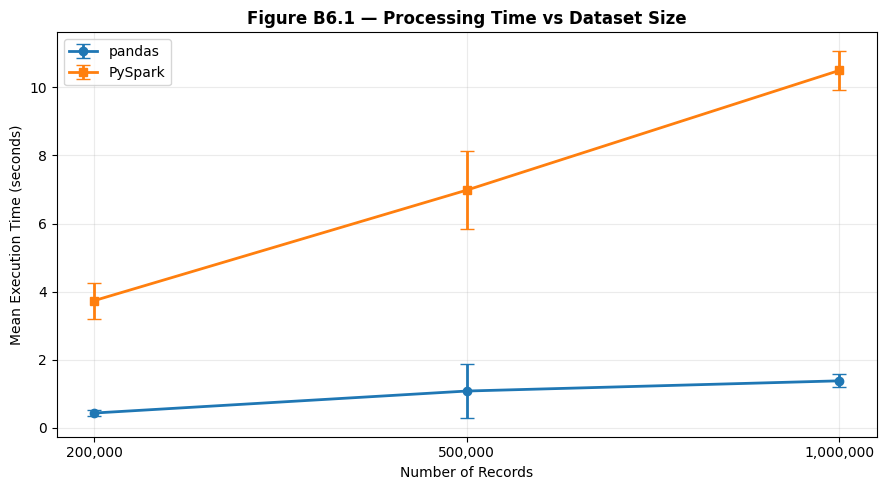

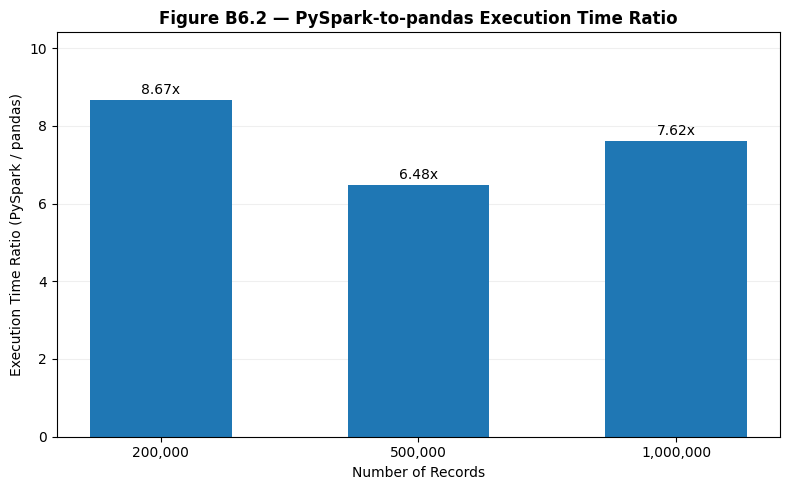

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/content/iiot_ca_results")

# Load experimental summary
b6 = pd.read_csv(
    OUT / "scalability_summary.csv"
)

# Dataset_Size is stored as a column after reading the CSV
b6 = b6.sort_values("Dataset_Size")

x = np.arange(len(b6))
labels = [f"{int(n):,}" for n in b6["Dataset_Size"]]

# Figure B6.1 — Mean execution time with standard deviation
fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    x,
    b6["Pandas_Mean"],
    yerr=b6["Pandas_Std"],
    marker="o",
    capsize=5,
    linewidth=2,
    label="pandas"
)

ax.errorbar(
    x,
    b6["Spark_Mean"],
    yerr=b6["Spark_Std"],
    marker="s",
    capsize=5,
    linewidth=2,
    label="PySpark"
)

ax.set_title(
    "Figure B6.1 — Processing Time vs Dataset Size",
    fontweight="bold"
)
ax.set_xlabel("Number of Records")
ax.set_ylabel("Mean Execution Time (seconds)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    OUT / "B6_processing_scalability.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure B6.2 — Relative execution time
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    labels,
    b6["Spark_to_Pandas_Ratio"],
    width=0.55
)

ax.set_title(
    "Figure B6.2 — PySpark-to-pandas Execution Time Ratio",
    fontweight="bold"
)
ax.set_xlabel("Number of Records")
ax.set_ylabel("Execution Time Ratio (PySpark / pandas)")
ax.set_ylim(0, b6["Spark_to_Pandas_Ratio"].max() * 1.2)

for bar, value in zip(bars, b6["Spark_to_Pandas_Ratio"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{value:.2f}x",
        ha="center"
    )

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    OUT / "B6_execution_time_ratio.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Figure B6.1 shows the evolution of the average processing time for pandas and PySpark across datasets containing 200,000, 500,000, and 1,000,000 records. The error bars represent the standard deviation from the five runs performed for each dataset.

> The results demonstrate that execution time increases with data volume for both technologies. However, pandas consistently showed shorter execution times than PySpark in all evaluated scenarios, indicating greater temporal efficiency under the experimental conditions used.

Figure B6.2 presents the ratio between the average execution times of PySpark and pandas for the three data volumes.

> The results indicate that PySpark was **8 times slower** for 200,000 records, **6 times slower** for 500,000, and **7 times slower** for 1,000,000.

Although the relative difference between the technologies varied according to data volume, pandas maintained a performance advantage in all experiments. No consistent trend toward a reduction in this gap was observed, nor was there any point at which PySpark outperformed pandas.

## B7 — Critical evaluation and MLO mapping
**MLO 1:** Compare CSV/Parquet size, read speed, schema compatibility, and discuss data-lake governance, schema evolution, metadata, and retention. **MLO 2:** Explain Spark driver/executors, partitioning, lazy execution, task scheduling, local vs cluster mode; compare MapReduce and streaming architectures conceptually. **MLO 3:** Justify technology choices from measured workload and limitations.

**Prior results (for comparison only; re-run for independent evidence):** 200k: pandas 0.4496s, Spark 5.0371s; 500k: 0.6171s vs 5.9124s; 1M: 0.7128s vs 6.8388s. These times are *historical outputs*, not generated by this notebook until re-executed.

**Limitations:** Spark local mode is not multi-node distributed computing; single machine; no full data-ingestion stream, fault tolerance, or distributed NN training. Also ensure the sampled records and features reflect the source data.

### B7 — Validation of Numerical Equivalence between pandas and PySpark

Following the performance and scalability assessment conducted in experiments B5 and B6, a numerical validation procedure was developed to verify the consistency of the statistical results produced by the pandas and PySpark libraries.

Comparing processing technologies should not rely solely on execution time. It is also necessary to verify whether different implementations yield compatible results when subjected to the same data and mathematical operations.

This verification is particularly relevant in parallel and distributed processing environments, where the order of operations and aggregation mechanisms may vary across different implementations.

According to Goldberg (1991), computational operations involving floating-point numbers are subject to limitations in precision and rounding. Consequently, mathematically equivalent results may exhibit minor numerical differences when calculated using different algorithms or execution sequences.

> -> In this context, Experiment B7 was designed to verify whether the statistical operations performed by pandas and PySpark yield numerically equivalent results, within predefined tolerances.

**Experimental Methodology**

The three datasets prepared in Experiment B2—containing 200,000, 500,000, and 1,000,000 records, respectively—were used.

Each dataset consists of 50 numerical attributes and a classification variable, `Attack_label`, stored in the Apache Parquet format.

For each data volume, the following procedures were carried out:

1. Reading the Parquet file using pandas and calculating the means and sample standard deviations for the 50 numerical attributes.
2. Reading the same file using PySpark and performing equivalent statistical operations using the `avg()` and `stddev_samp()` functions.
3. Converting the results into comparable numerical structures. 4. Comparison of values ​​using the `numpy.allclose()` function, with defined relative and absolute tolerances.
5. Recording of validation results for each dataset size.

In pandas, the standard deviation was calculated using `std(ddof=1)`, while in PySpark, the `stddev_samp()` function was used.

Both represent the sample standard deviation, allowing for a methodologically consistent comparison.

Equivalence was verified using the `numpy.allclose()` function, with the following parameters:

| Parameter | Value | Purpose |
|---|---|---|
| `rtol` | `1e-5` | Relative tolerance |
| `atol` | `1e-8` | Absolute tolerance |
| `equal_nan` | `True` | Treat `NaN` values ​​in the same positions as equivalent |

The function considers two values ​​to be numerically close when the absolute difference between them satisfies the following condition:

\[
|a-b| \leq atol + rtol \times |b|
\]

This approach is appropriate for comparing the results of operations involving floating-point numbers, where minor rounding differences may occur.

We organized the results into a table containing the size of each dataset and two boolean indicators: `Means_Match` and `Standard_Deviations_Match`.

Finally, the validation table was exported to the file `numerical_equivalence.csv`, allowing for the documentation of results and the preservation of experimental evidence.

The objective of this step is not to demonstrate exact equality between the results, but rather to verify their numerical consistency within the established tolerances.

Reference:

1. Goldberg, D. (1991) 'What Every Computer Scientist Should Know About Floating-Point Arithmetic', ACM Computing Surveys, 23(1), pp. 5–48. https://doi.org/10.1145/103162.103163

In [ ]:

# B7 — Numerical Equivalence Validation
# Big Data Storage and Processing — MLO 3

import numpy as np
import pandas as pd
from pyspark.sql import functions as F

validation_results = []

for size in SIZES:

    path = paths[size]

    # Pandas calculations
    pdf = pd.read_parquet(path)

    pandas_means = pdf[feature_cols].mean()
    pandas_stds = pdf[feature_cols].std(ddof=1)

    # Spark calculations
    sdf = spark.read.parquet(str(path))

    expressions = []

    for col in feature_cols:
        safe_col = F.col(
            "`" + col.replace("`", "``") + "`"
        )

        expressions.append(
            F.avg(safe_col).alias(col + "_mean")
        )

        expressions.append(
            F.stddev_samp(safe_col).alias(col + "_std")
        )

    spark_result = sdf.agg(*expressions).collect()[0].asDict()

    spark_means = np.array([
        spark_result[col + "_mean"]
        for col in feature_cols
    ], dtype=float)

    spark_stds = np.array([
        spark_result[col + "_std"]
        for col in feature_cols
    ], dtype=float)

    # Compare using numerical tolerances
    means_match = np.allclose(
        pandas_means.to_numpy(dtype=float),
        spark_means,
        rtol=1e-5,
        atol=1e-8,
        equal_nan=True
    )

    stds_match = np.allclose(
        pandas_stds.to_numpy(dtype=float),
        spark_stds,
        rtol=1e-5,
        atol=1e-8,
        equal_nan=True
    )

    validation_results.append({
        "Dataset_Size": size,
        "Means_Match": means_match,
        "Standard_Deviations_Match": stds_match
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

validation_df.to_csv(
    OUT / "numerical_equivalence.csv",
    index=False
)

print("\nB7 numerical validation completed!")


,Dataset_Size,Means_Match,Standard_Deviations_Match
0,200000,True,True
1,500000,True,True
2,1000000,True,True



B7 numerical validation completed!


### B7 — Numerical Equivalence Validation Results

The execution of Experiment B7 allowed for the verification of the numerical equivalence of the sample means and standard deviations calculated using the pandas and PySpark libraries.

The validation was performed on the three previously prepared experimental datasets, containing 200,000, 500,000, and 1,000,000 records, respectively.


**Table B7.1 — Numerical validation results**

| Records | Equivalence of means | Equivalence of standard deviations |
|---|---|---|
| 200,000 | `True` | `True` |
| 500,000 | `True` | `True` |
| 1,000,000 | `True` | `True` |

The results demonstrate that the sample means and standard deviations produced by pandas and PySpark were numerically equivalent across all evaluated datasets, within the established tolerances.

**Validation of means**

The comparison of the means returned `True` for all three data volumes.

> This indicates that the results calculated by pandas and PySpark exhibited differences small enough to satisfy the defined criteria for numerical proximity.

Since the validation accounted for the 50 numerical attributes in each dataset, the results provide evidence of consistency between the implementations for the mean calculations evaluated.

**Validation of standard deviations**

The comparison of the sample standard deviations also returned `True` for all experimental datasets.

> This result is significant because the calculation of the standard deviation involves additional operations, including the assessment of the dispersion of values ​​relative to the mean. The use of `ddof=1` in pandas and `stddev_samp()` in PySpark ensured that both implementations utilized the definition of sample standard deviation.

**Discussion of results**

> >**The results of Experiment B7 complement the evaluations conducted in experiments B5 and B6.**

Although significant differences in processing times were observed between pandas and PySpark, the validation demonstrated that both technologies produced numerically equivalent statistical results for the data and operations analyzed.

This strengthens the interpretation of the previous benchmarks, as it indicates that the performance comparison was conducted between implementations that yield compatible results within established tolerances.

However, the observed numerical equivalence does not imply exact equality across all values, nor does it guarantee the absence of discrepancies in other analytical operations.

Furthermore, the use of `equal_nan=True` treats missing values ​​in the same positions as equivalent. Therefore, this validation should be interpreted specifically within the context of the numerical criteria applied.

Overall, Experiment B7 achieved its objective of verifying the consistency of the statistical calculations performed by both technologies, concluding the experimental sequence in Notebook 1.